# Detección de arritmias intraoperatorias con ML tradicional
## VitalDB Arrhythmia Database (PhysioNet)

**Proyecto final, Fundamentos de Aprendizaje Automático, EAFIT**

Notebook de desarrollo del modelo (`model_development.ipynb`). Cada fase tiene su explicación en markdown, su bloque de código y una celda de **interpretación** escrita a partir de los resultados de la ejecución completa con los 482 casos.

**Índice**

0. Introducción y problema
1. Descripción del dataset
2. Preparación del entorno (local y Google Colab)
3. Carga de datos
4. Exploración inicial
5. Armonización y limpieza de etiquetas
6. Análisis exploratorio (EDA)
7. Preprocesamiento de la señal ECG
8. Construcción de ventanas y características
9. Exploración no supervisada
10. Partición por paciente
11. Modelado y selección de hiperparámetros
12. Evaluación en test
13. Explicabilidad
14. Evidencia de generalización y ausencia de fuga de datos
15. Guardado del modelo y despliegue
16. Estrategia de monitoreo y reentrenamiento
17. Conclusiones, limitaciones y trabajo futuro
18. Referencias

---
# 0. Introducción y problema

## 0.1 Contexto clínico

Una **arritmia** es una alteración del ritmo cardíaco. Durante una cirugía, la anestesia, los fármacos, el estímulo quirúrgico y los cambios del sistema nervioso autónomo hacen que las arritmias sean frecuentes. La mayoría son benignas, pero algunas (fibrilación auricular con respuesta rápida, taquicardia ventricular, bloqueos) exigen una intervención inmediata, y tratarlas tarde aumenta la morbimortalidad.

El anestesiólogo vigila al paciente en un monitor y debe atender a la vez muchas otras tareas. Un sistema que **señale automáticamente los tramos de ECG con ritmo anormal** reduce la carga de vigilancia y acelera la respuesta.

Según los autores del dataset en PhysioNet, las bases de ECG públicas existentes provienen sobre todo de ambientes **ambulatorios (Holter) y de cuidados intensivos**, y no representan el entorno quirúrgico, que tiene sus propias características fisiológicas y técnicas (electrocauterio, movimiento, ventilación mecánica, fármacos anestésicos). Estas son las razones que motivan el dataset y este proyecto.

## 0.2 Problema que abordamos

> **Clasificar, a partir de ventanas cortas de ECG de una derivación (derivación II), el ritmo cardíaco de un paciente en cirugía**, distinguiendo ritmo sinusal normal de arritmias clínicamente relevantes y de tramos con ruido, usando **aprendizaje supervisado tradicional** (no redes profundas).

- **Usuarios**: anestesiólogos, técnicos y enfermería de quirófano o recuperación; también investigadores que quieran revisar grabaciones largas.
- **Decisión que se apoya**: qué tramos de una grabación revisar primero y si el ritmo actual podría requerir intervención. El modelo **asiste, no diagnostica**.
- **Tipo de problema**: clasificación multiclase desbalanceada, con una clase de ruido, validada por paciente.
- **Por qué ML tradicional**: la arritmia deja huellas medibles en la señal (irregularidad de los intervalos RR en la fibrilación auricular, frecuencia alta en las taquicardias, patrones periódicos en las ectopias) que se resumen bien en **características diseñadas a mano** interpretables. Esto permite modelos livianos, explicables con SHAP y desplegables sin GPU.

## 0.3 Preguntas guía

1. ¿Qué tan separables son los ritmos usando solo características de intervalos RR y calidad de señal?
2. ¿Qué clases son difíciles (y por qué) y cuáles hay que fusionar o descartar por falta de datos?
3. ¿Generaliza el modelo a pacientes que nunca vio?
4. ¿Cómo se detectaría que el modelo se degrada en producción y cómo se reentrena?

## 0.4 Alcance y cumplimiento de los requisitos del curso

| Requisito del PDF | Dónde se cumple |
|---|---|
| Problema real, usuarios, decisión, fuente | Secciones 0 y 1 |
| Preprocesamiento documentado | Secciones 5, 7 y 8 |
| EDA profunda con insights | Secciones 4, 6 y 9 |
| Paradigma de ML | Supervisado (clasificación), con apoyo no supervisado en la sección 9 |
| Metodología, selección de modelo e hiperparámetros | Secciones 10 y 11 |
| Generalización sin sobreajuste ni fuga | Secciones 10 y 14 |
| Métricas justificadas | Secciones 11 y 12 |
| Modelo desplegado con interfaz | Sección 15 (`app/app.py`) |
| Reentrenamiento y drift | Sección 16 |

---
# 1. Descripción del dataset

## 1.1 Ficha

| Campo | Valor |
|---|---|
| Nombre | **VitalDB Arrhythmia Database: An Anesthesiologist-Validated Large-Scale Intraoperative Arrhythmia Dataset with Beat and Rhythm Labels** |
| Autores | Dain Eun, Kayoung Shim, Hyunsoo Lee, Yeji Lim, Hanbyeol Lim, Hyeonhoon Lee, Hyung-Chul Lee |
| Publicación | 26 de febrero de 2026, versión 1.0.0 en PhysioNet |
| DOI | 10.13026/axd6-wm13 |
| Licencia | Creative Commons Attribution 4.0 (CC BY 4.0), acceso abierto |
| Tamaño del paquete | 20.9 MB (anotaciones y metadatos); ZIP de 3.4 MB |
| Repositorio de los autores | https://github.com/vitaldb/arrdb |
| Dataset padre | VitalDB (Lee et al., *Sci Data* 2022), Hospital Universitario Nacional de Seúl (SNUH) |
| Ética | VitalDB es un conjunto desidentificado y público del SNUH, aprobado por su comité de ética (H-1408-101-605). No hay fechas absolutas: todo el tiempo es relativo al inicio de la grabación |

## 1.2 Origen y cómo se construyó

Los autores partieron del **dataset abierto VitalDB**, que recoge señales vitales de alta fidelidad de pacientes en cirugía del SNUH. Construyeron la base en dos etapas:

1. **Cribado automático de candidatos.** Entrenaron un clasificador de latidos de aprendizaje profundo (**UniMS-ECGNet**) con datos de VitalDB, de MIT-BIH Arrhythmia y de la CU Ventricular Tachyarrhythmia Database. Con él marcaron segmentos candidatos según criterios como latidos anormales consecutivos, alta variabilidad del intervalo R-R o ectopias con patrón.
2. **Anotación y validación clínica.** Un panel de **cinco anestesiólogos** revisó los segmentos; cada uno fue etiquetado de forma independiente por **al menos dos** médicos hasta llegar a un consenso. Concordancia entre evaluadores: **kappa de Cohen de 0.930 ± 0.130**.

> **Consecuencia importante para el modelado:** los segmentos *no* son una muestra aleatoria de la cirugía. Fueron preseleccionados porque *parecían* arrítmicos. La prevalencia de arritmias en este dataset es mucho mayor que la real, y un modelo entrenado aquí no estima la prevalencia real en quirófano.

## 1.3 Qué contiene

- **734,528 segundos** (unas 204 horas) de ECG continuo anotado de **482 pacientes** quirúrgicos.
- Más de **660,000 latidos** anotados individualmente.
- **4 tipos de latido** (`beat_type`): Normal (N), Supraventricular (S), Ventricular (V), Inclasificable (U).
- **10 categorías de ritmo** más la etiqueta de ruido.
- Cada caso trae unos **20 minutos** de anotación, no toda la cirugía.

### Archivos

- `metadata.csv`: una fila por caso, con `case_id`, `analyzed_duration_sec`, `total_beats`, `rhythm_classes` y datos quirúrgicos y clínicos (edad, sexo, IMC, ASA, tipo de operación, laboratorios preoperatorios, variables intraoperatorias).
- `Annotation_Files/Annotation_file_[case_id].csv`: un archivo por caso con una fila por latido:

| Columna | Significado |
|---|---|
| `time_second` | Instante del pico R, en segundos desde el inicio de la grabación |
| `beat_type` | Tipo de latido (N, S, V, U) |
| `rhythm_label` | Ritmo del segmento al que pertenece el latido |
| `bad_signal_quality` | Booleano: el latido está en un tramo con ruido que impide interpretar P o T |
| `bad_signal_quality_label` | Marca de inicio o fin de ese tramo (`Start1`, `End1`, ...) |

- **La señal ECG no está en el paquete.** Se descarga de VitalDB con el `case_id`, canal `SNUADC/ECG_II`, a **500 Hz**, con el paquete `vitaldb`.

## 1.4 Distribución publicada por los autores

| Ritmo | Casos | Latidos | Duración (s) |
|---|---:|---:|---:|
| Ritmo sinusal normal | 370 | 408,420 | 384,407 |
| Ruido | 250 | - | 67,734 |
| Fibrilación auricular | 111 | 163,270 | 121,888 |
| Ectopia ventricular con patrón | 109 | 24,069 | 47,481 |
| Taquiarritmia supraventricular | 109 | 6,416 | 14,799 |
| Taquiarritmia ventricular | 88 | 1,598 | 9,927 |
| Ectopia auricular con patrón | 85 | 20,326 | 40,600 |
| Disfunción del nodo sinusal | 66 | 23,141 | 31,942 |
| Marcapasos auricular errante / ritmo auricular multifocal | 26 | 10,132 | 9,630 |
| Bloqueo auriculoventricular | 10 | 4,323 | 5,486 |
| Inclasificable | 6 | 199 | 631 |

## 1.5 Etiquetas de calidad de señal

- **Bad signal quality**: se ven los complejos QRS pero el ruido oculta la onda P o T. Puede coexistir con otra etiqueta de ritmo.
- **Noise**: el artefacto es tan severo que **no se detectan complejos QRS**. Esos segmentos **no tienen anotaciones de latidos**.

## 1.6 Limitaciones declaradas

- Anotación concentrada en segmentos candidatos de ~20 minutos por caso.
- Un solo hospital, una sola población (coreana), un solo tipo de monitor.
- Los segmentos se eligieron con un modelo de IA, lo que introduce **sesgo de selección**.

## 1.7 Implicaciones para este proyecto

| Hallazgo del dataset | Decisión de diseño |
|---|---|
| Desbalance fuerte (TV 1,598 latidos, BAV 10 casos) | Fusionar o descartar clases raras, `class_weight`, métricas macro y por clase |
| Varios ritmos por caso | Etiquetar por **ventana**, no por paciente |
| Muchos casos y pocos pacientes repetidos | Validar **por paciente** (`GroupKFold`) |
| El ruido no tiene latidos | Necesita características de **señal**, no solo de RR |
| `beat_type` es una etiqueta humana | **No** puede ser variable de entrada si el modelo debe funcionar sobre ECG crudo |
| Un solo hospital | La generalización a otros hospitales queda **sin probar** y se declara |

---
# 2. Preparación del entorno

El notebook corre igual en local (VS Code o Jupyter) y en **Google Colab**. En Colab se monta Google Drive y se espera que la carpeta del proyecto esté en `MyDrive/FundamentosML-Final` (ajusta `RUTA_DRIVE` si la tuya es otra). Los datos van en `data/` dentro de esa carpeta (ver `README.md`).

In [1]:
# Configuración del entorno: local o Google Colab
import sys, subprocess
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
RUTA_DRIVE = "/content/drive/MyDrive/FundamentosML-Final"   # <-- ajustar si hace falta

def pip_install(*paquetes):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *paquetes])

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path(RUTA_DRIVE)
    pip_install("vitaldb", "shap")
else:
    RAIZ = Path.cwd()          # abrir el notebook desde la raiz del proyecto

assert (RAIZ / "src" / "ecg_utils.py").exists(), f"No encuentro src/ecg_utils.py en {RAIZ}. Revisa RAIZ."
sys.path.insert(0, str(RAIZ / "src"))
print("Raíz del proyecto:", RAIZ)

Raíz del proyecto: c:\Universidad EAFIT - Ing. de Sistemas\Fund. Aprendizaje Automático\FundamentosML-Final


In [2]:
# Importaciones
import json, warnings, time
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, balanced_accuracy_score,
                             classification_report, confusion_matrix, f1_score, matthews_corrcoef,
                             precision_recall_curve)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedGroupKFold, cross_val_predict,
                                     cross_validate, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import SVC
from scipy import stats

import ecg_utils as eu

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
SEMILLA = 42
np.random.seed(SEMILLA)

In [3]:
# Rutas y parámetros del experimento (todo lo ajustable vive aquí)
DATA_DIR  = RAIZ / "data"
ANN_DIR   = DATA_DIR / "Annotation_Files"
META_CSV  = DATA_DIR / "metadata.csv"
ECG_DIR   = DATA_DIR / "ecg_cache"
MODELOS   = RAIZ / "models"; MODELOS.mkdir(exist_ok=True)
FIGURAS   = RAIZ / "figures"; FIGURAS.mkdir(exist_ok=True)

FS             = eu.FS      # 500 Hz
VENTANA_S      = 10         # duración de cada ventana en segundos (los episodios de TV/SVTA duran pocos segundos)
PASO_S         = 10         # paso entre ventanas (= VENTANA_S: sin solapamiento)
MIN_LATIDOS    = 6          # mínimo de latidos para una ventana con ritmo (no aplica a Ruido)
PUREZA_MIN     = 0.80       # fracción mínima de la ventana cubierta por el ritmo mayoritario
EVENTOS_CORTOS = {"TV": 3, "SVTA": 3}   # ritmos que dominan la ventana si tienen >= N latidos (salvas breves)
MAX_POR_CLASE  = 5000       # tope de ventanas por clase para entrenar (None = sin tope); ver sección 8.3
MAX_CASOS      = None       # poner p.ej. 40 para una prueba rápida
FUENTE_PICOS   = "anotados" # "anotados" (rápido) o "detectados" (realista, usa el detector sobre la señal)
USAR_SENAL     = True       # incluir características de la señal (necesita ECG en data/ecg_cache)
CLASES_MIN_VENTANAS = 60    # clases con menos ventanas se fusionan/descartan (sección 5)

---
# 3. Carga de datos

Se cargan dos fuentes:

1. **Metadatos** (`metadata.csv`): una fila por caso.
2. **Anotaciones latido a latido**: se concatenan los 482 archivos en un solo DataFrame con la columna `case_id`.

Las señales ECG se cargan más adelante, solo cuando se necesitan, desde la caché local.

In [4]:
assert META_CSV.exists(), "Falta data/metadata.csv. Sigue README.md o ejecuta descargar_datos.py"
meta = pd.read_csv(META_CSV)
# La edad viene como texto: VitalDB reemplaza las edades mayores de 89 por ">89" (desidentificación)
meta["age"] = pd.to_numeric(meta["age"].astype(str).str.replace(">", "", regex=False), errors="coerce")
if MAX_CASOS:
    meta = meta.head(MAX_CASOS)
print("Metadatos:", meta.shape)
meta.head(3)

Metadatos: (482, 79)


,case_id,analysis_start_time_sec,analysis_end_time_sec,analyzed_duration_sec,total_beats,rhythm_classes,subjectid,casestart,caseend,anestart,...,intraop_colloid,intraop_ppf,intraop_mdz,intraop_ftn,intraop_rocu,intraop_vecu,intraop_eph,intraop_phe,intraop_epi,intraop_ca
0,1001,4993.494444,6188.511111,1195.016667,1047,"N, Patterned Ventricular Ectopy",2077,0,9347,-1657,...,0,0,0.0,0,60,0,10,80,0,300
1,1002,6153.197222,7352.455556,1199.258333,1466,"N, Noise, SVTA",1877,0,9766,-47,...,0,0,0.0,0,70,0,10,0,0,0
2,1018,1523.447222,2541.350000,1017.902778,1087,"N, SVTA, VT",1230,0,25733,-861,...,200,0,0.0,0,80,0,55,0,80,1200


In [5]:
def cargar_anotaciones(ids):
    partes = []
    for cid in ids:
        ruta = ANN_DIR / f"Annotation_file_{cid}.csv"
        if not ruta.exists():
            continue
        d = pd.read_csv(ruta)
        d = d.drop(columns=["caseid"], errors="ignore")   # el archivo 2453 trae una columna extra con ese nombre
        d.insert(0, "case_id", cid)
        partes.append(d)
    return pd.concat(partes, ignore_index=True)

ann = cargar_anotaciones(meta["case_id"])
ann["bad_signal_quality"] = ann["bad_signal_quality"].astype(str).str.lower().isin(["true", "1"])
print("Anotaciones:", ann.shape, "| casos con archivo:", ann.case_id.nunique())
ann.head()

Anotaciones: (676250, 6) | casos con archivo: 482


,case_id,time_second,beat_type,rhythm_label,bad_signal_quality,bad_signal_quality_label
0,1001,4993.494444,N,N,False,NaN
1,1001,4994.586111,N,N,False,NaN
2,1001,4995.672222,N,N,False,NaN
3,1001,4996.788889,N,N,False,NaN
4,1001,4998.036111,N,N,False,NaN


In [6]:
# ¿Cuántas señales ECG tenemos ya en la caché local?
casos_con_ecg = [c for c in meta.case_id if eu.ruta_cache(c, ECG_DIR).exists()]
print(f"ECG en caché: {len(casos_con_ecg)} de {len(meta)} casos")
if USAR_SENAL and not casos_con_ecg:
    print("AVISO: no hay ECG descargado. Ejecuta descargar_datos.py o pon USAR_SENAL=False (se pierde la clase Ruido).")

ECG en caché: 482 de 482 casos


---
# 4. Exploración inicial

Antes de limpiar nada se revisa la estructura: tipos, nulos, valores únicos y rangos. El objetivo es descubrir **cómo están escritas realmente las etiquetas** (el nombre exacto de las clases y cómo aparece el ruido), porque la armonización de la sección 5 depende de ello.

In [7]:
print("== Metadatos ==")
display(meta.dtypes.value_counts().rename("n_columnas").to_frame())
nulos = meta.isna().mean().sort_values(ascending=False)
print("\nColumnas con más del 30% de nulos:", (nulos > 0.3).sum(), "de", meta.shape[1])
display(nulos.head(15).round(3).to_frame("fraccion_nulos"))

== Metadatos ==


,n_columnas
float64,32
int64,27
str,20



Columnas con más del 30% de nulos: 13 de 79


,fraccion_nulos
lmasize,0.985
cline2,0.965
aline2,0.925
preop_be,0.876
preop_sao2,0.873
preop_hco3,0.873
preop_ph,0.873
preop_paco2,0.873
preop_pao2,0.873
dltubesize,0.801


In [8]:
print("== Anotaciones ==")
print("beat_type:\n", ann["beat_type"].value_counts(dropna=False).to_string())
print("\nrhythm_label (originales):\n", ann["rhythm_label"].value_counts(dropna=False).to_string())
print("\nbad_signal_quality:", ann["bad_signal_quality"].mean().round(4), "fracción de latidos marcados")
print("\nValores no nulos de bad_signal_quality_label (muestra):",
      ann["bad_signal_quality_label"].dropna().unique()[:8])

== Anotaciones ==
beat_type:
 beat_type
N        439458
S        184203
U         18972
NaN       17364
V         16234
P             7
Start         6
End           6

rhythm_label (originales):
 rhythm_label
N                               408420
AFIB/AFL                        163270
Patterned Ventricular Ectopy     24069
SND                              23141
Patterned Atrial Ectopy          20326
WAP/MAT                          10132
Noise                            10098
SVTA                              6416
AVB                               4323
NaN                               4258
VT                                1598
Unclassifiable                     199

bad_signal_quality: 0.0517 fracción de latidos marcados

Valores no nulos de bad_signal_quality_label (muestra): ['Start1' 'End1' 'Start2' 'End2' 'Start3' 'End3' 'Start4' 'End4']


In [9]:
# ¿Cómo aparece el ruido en los archivos? (no tiene latidos anotados según la documentación)
ruido = ann[ann["rhythm_label"].astype(str).str.lower().str.contains("noise")]
print("Filas con rhythm_label de ruido:", len(ruido), "| casos:", ruido.case_id.nunique())
display(ruido.head(8))
print("\nbeat_type en filas de ruido:\n", ruido["beat_type"].value_counts(dropna=False).to_string())

Filas con rhythm_label de ruido: 10098 | casos: 250


,case_id,time_second,beat_type,rhythm_label,bad_signal_quality,bad_signal_quality_label
1224,1002,6300.888889,NaN,Noise,True,NaN
1225,1002,6301.738889,NaN,Noise,True,NaN
1226,1002,6302.588889,NaN,Noise,True,NaN
1227,1002,6304.277778,NaN,Noise,True,NaN
1228,1002,6305.972222,NaN,Noise,True,NaN
1229,1002,6308.358333,NaN,Noise,True,End1
1230,1002,6308.516667,NaN,Noise,False,NaN
2018,1002,6880.230556,NaN,Noise,True,NaN



beat_type en filas de ruido:
 beat_type
NaN    10098


### Interpretación

- **Metadatos**: 482 casos y 79 columnas. 13 columnas tienen más del 30 % de nulos (tamaño de máscara laríngea 98.5 %, gases arteriales preoperatorios ~87 %, accesos venosos y arteriales secundarios). Son variables quirúrgicas que no existen para todos los pacientes; no se usan como predictores porque el modelo debe funcionar solo con la señal.
- **Etiquetas**: `rhythm_label` usa abreviaturas (`N`, `AFIB/AFL`, `SVTA`, `VT`, `SND`, `AVB`, `WAP/MAT`, `Noise`...) que `normalizar_ritmo` cubre todas. Hay 4,258 filas sin ritmo: son marcadores de inicio y fin de mala calidad (`Start`, `End`, filas sin tipo de latido) y algunos latidos aislados sin etiqueta.
- **Ruido**: aparece en 250 casos como 10,098 filas con `rhythm_label = Noise`, **sin tipo de latido** (`beat_type` vacío) pero con tiempo. Es decir, el ruido sí tiene marcas temporales y por eso se puede delimitar en el tiempo para construir sus ventanas.
- **Calidad**: el 5.2 % de los latidos está marcado con `bad_signal_quality`.

---
# 5. Armonización y limpieza de etiquetas

Decisiones de preprocesamiento (todas se documentan para la presentación):

1. **Normalizar los nombres de ritmo** a un vocabulario único (`ecg_utils.normalizar_ritmo`).
2. **Quitar filas que no son latidos**: marcadores `Start`/`End` de mala calidad y filas sin tipo ni ritmo.
3. **Ordenar por tiempo** dentro de cada caso, eliminar duplicados exactos y **rellenar** los latidos reales que quedaron sin ritmo con el del latido vecino.
4. **Clases raras**: Bloqueo AV (10 casos) e Inclasificable (6 casos) no tienen datos para entrenar ni evaluar con rigor por paciente. Se descartan o se fusionan más adelante según el conteo real de ventanas (`CLASES_MIN_VENTANAS`).
5. **No se usa `beat_type` como predictor**: es una anotación humana que no existe cuando llega un ECG nuevo.

In [10]:
# 1) Quitar filas que no son latidos: marcadores Start/End de mala calidad y filas sin tipo ni ritmo
es_marcador = ann["beat_type"].isin(["Start", "End"]) | (ann["beat_type"].isna() & ann["rhythm_label"].isna())
print(f"Filas marcadoras descartadas: {es_marcador.sum()}")
ann = ann[~es_marcador].copy()

# 2) Ordenar, quitar duplicados exactos y normalizar los nombres de ritmo
ann = (ann.dropna(subset=["time_second"]).sort_values(["case_id", "time_second"])
          .drop_duplicates(subset=["case_id", "time_second", "rhythm_label"]).reset_index(drop=True))
ann["ritmo"] = ann["rhythm_label"].map(eu.normalizar_ritmo)

# 3) Latidos reales sin ritmo (valor faltante dentro de un segmento): heredar el del latido vecino del mismo caso
faltan = ann["ritmo"].eq("Sin etiqueta")
print(f"Latidos sin etiqueta de ritmo: {faltan.sum()} (se rellenan con el vecino)")
ann.loc[faltan, "ritmo"] = np.nan
ann["ritmo"] = ann.groupby("case_id")["ritmo"].transform(lambda s: s.ffill().bfill())

sin_mapa = ann.loc[ann["ritmo"].isin(["Otro"]), "rhythm_label"].value_counts()
print("Etiquetas sin mapear:", sin_mapa.to_dict() if len(sin_mapa) else "ninguna")
print("Filas finales:", len(ann))
ann["ritmo"].value_counts()

Filas marcadoras descartadas: 3443
Latidos sin etiqueta de ritmo: 827 (se rellenan con el vecino)
Etiquetas sin mapear: ninguna
Filas finales: 672656


ritmo
Normal                     408869
AFib                       163269
Ectopia ventricular         24145
Disfuncion nodo sinusal     23156
Ectopia auricular           20344
WAP/MAT                     10134
Ruido                       10117
SVTA                         6483
Bloqueo AV                   4320
TV                           1618
Inclasificable                201
Name: count, dtype: int64

In [11]:
# Comparación con la tabla publicada por los autores (control de calidad de la carga)
publicado = pd.DataFrame({
    "Normal": [370, 408420], "Ruido": [250, np.nan], "AFib": [111, 163270], "Ectopia ventricular": [109, 24069],
    "SVTA": [109, 6416], "TV": [88, 1598], "Ectopia auricular": [85, 20326],
    "Disfuncion nodo sinusal": [66, 23141], "WAP/MAT": [26, 10132], "Bloqueo AV": [10, 4323],
    "Inclasificable": [6, 199]}, index=["casos_publicados", "latidos_publicados"]).T
obs = pd.DataFrame({"casos_en_tu_carga": ann.groupby("ritmo").case_id.nunique(),
                    "latidos_en_tu_carga": ann[ann.ritmo != "Ruido"].groupby("ritmo").size()})
display(publicado.join(obs))

,casos_publicados,latidos_publicados,casos_en_tu_carga,latidos_en_tu_carga
Normal,370.0,408420.0,370,408869.0
Ruido,250.0,NaN,250,NaN
AFib,111.0,163270.0,111,163269.0
Ectopia ventricular,109.0,24069.0,109,24145.0
SVTA,109.0,6416.0,109,6483.0
TV,88.0,1598.0,88,1618.0
Ectopia auricular,85.0,20326.0,85,20344.0
Disfuncion nodo sinusal,66.0,23141.0,66,23156.0
WAP/MAT,26.0,10132.0,26,10134.0
Bloqueo AV,10.0,4323.0,10,4320.0


### Interpretación

La carga coincide con la tabla publicada: los 482 casos, el mismo número de casos por ritmo (370 Normal, 111 AFib, 88 TV, 10 Bloqueo AV, etc.) y prácticamente los mismos latidos (diferencias menores al 1 %, que vienen de rellenar los 827 latidos sin ritmo con el de su vecino). La limpieza descartó 3,443 filas marcadoras que no eran latidos. Las clases con menos de 15 casos son **Bloqueo AV (10)** e **Inclasificable (6)**: son las candidatas a quedar fuera.

---
# 6. Análisis exploratorio (EDA)

El EDA responde preguntas que **cambian decisiones** de modelado:

| Pregunta | Decisión que informa |
|---|---|
| ¿Qué tan desbalanceadas están las clases (casos, latidos, tiempo)? | Métricas, `class_weight`, fusión de clases |
| ¿Cuántos ritmos conviven en un mismo paciente? | Etiquetar por ventana y particionar por paciente |
| ¿Cuánto ruido hay y dónde? | Clase Ruido, filtros de calidad |
| ¿Cómo difieren los intervalos RR entre ritmos? | Qué características diseñar |
| ¿Hay sesgos demográficos o clínicos? | Limitaciones y riesgo de generalización |

## 6.1 Distribución de clases

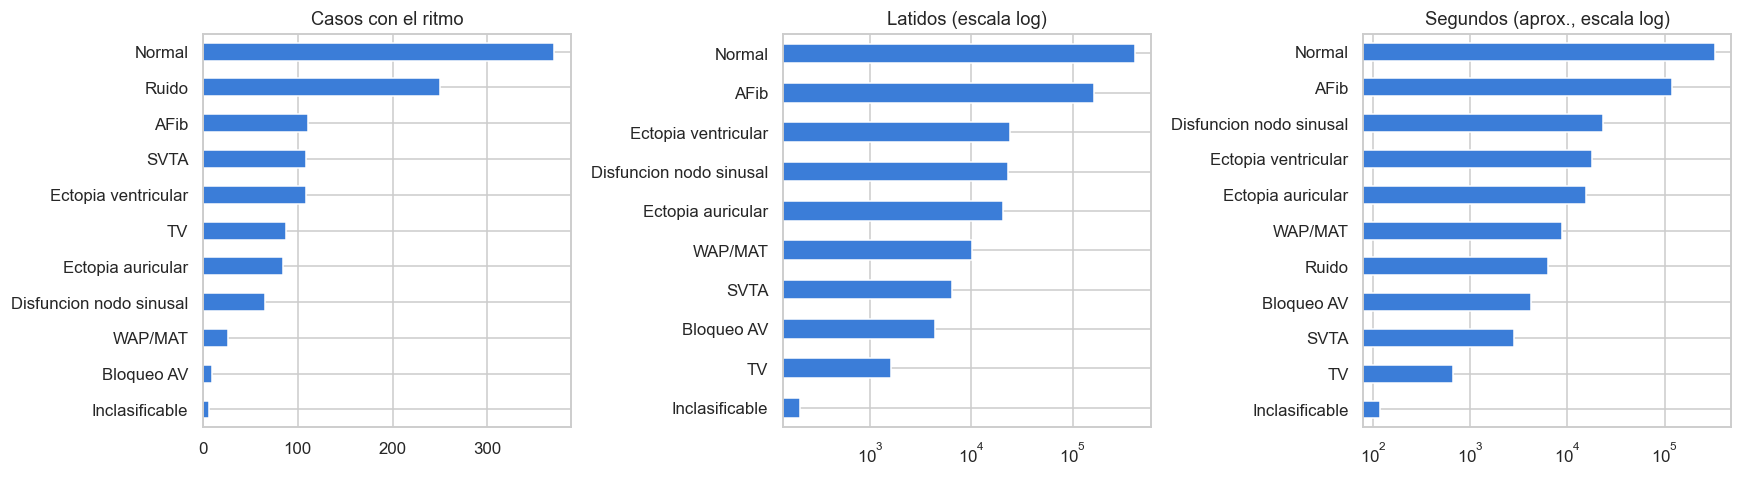

In [12]:
casos = ann.groupby("ritmo").case_id.nunique()
latidos = ann[ann.ritmo != "Ruido"].groupby("ritmo").size()

def segundos_por_ritmo(df):
    # duración aproximada: suma de dt entre latidos consecutivos del mismo ritmo (dt < 3 s)
    out = Counter()
    for _, g in df.groupby("case_id"):
        t, r = g.time_second.values, g.ritmo.values
        dt = np.diff(t)
        ok = (dt < 3.0) & (r[:-1] == r[1:])
        for rit, d in zip(r[:-1][ok], dt[ok]):
            out[rit] += d
    return pd.Series(out)
segs = segundos_por_ritmo(ann)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, s, tit in zip(ax, [casos, latidos, segs], ["Casos con el ritmo", "Latidos (escala log)", "Segundos (aprox., escala log)"]):
    s = s.sort_values()
    s.plot.barh(ax=a, color="#3b7dd8"); a.set_title(tit); a.set_ylabel("")
ax[1].set_xscale("log"); ax[2].set_xscale("log")
plt.tight_layout(); plt.savefig(FIGURAS / "eda_distribucion_clases.png"); plt.show()

**Interpretación.** Normal domina en casos (370), latidos (~409 mil) y tiempo. El desbalance es extremo: entre Normal y TV hay más de dos órdenes de magnitud en latidos (≈409 mil frente a ≈1.6 mil). Ruido aparece en muchos casos (250) pero dura poco en total, y TV aparece en 88 casos con muy pocos latidos, lo que indica episodios muy breves. Un clasificador que siempre diga "Normal" tendría una exactitud alta, por eso **la exactitud global no sirve** y se usan recall por clase, F1 macro y PR-AUC.

count    482.00
mean       2.55
std        0.97
min        1.00
25%        2.00
50%        2.00
75%        3.00
max        6.00


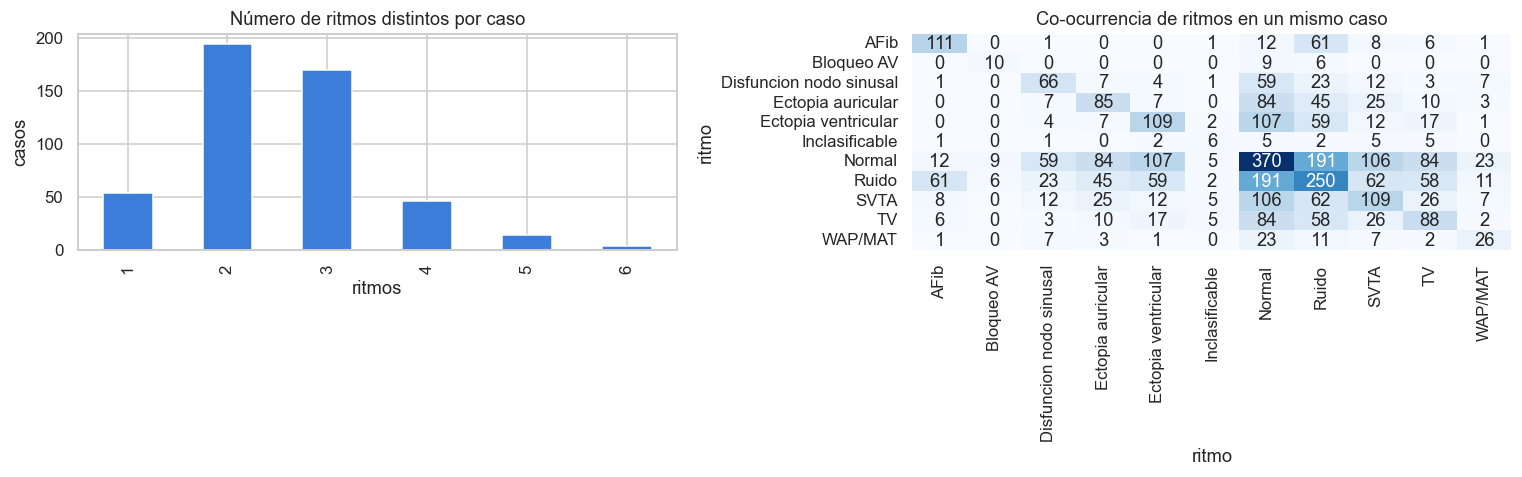

In [13]:
rit_por_caso = ann.groupby("case_id").ritmo.nunique()
print(rit_por_caso.describe().round(2).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
rit_por_caso.value_counts().sort_index().plot.bar(ax=ax[0], color="#3b7dd8")
ax[0].set_title("Número de ritmos distintos por caso"); ax[0].set_xlabel("ritmos"); ax[0].set_ylabel("casos")

co = pd.crosstab(ann.case_id, ann.ritmo).clip(upper=1)
matriz = co.T.dot(co)
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", ax=ax[1], cbar=False)
ax[1].set_title("Co-ocurrencia de ritmos en un mismo caso")
plt.tight_layout(); plt.savefig(FIGURAS / "eda_coocurrencia.png"); plt.show()

**Interpretación.** Solo unos 50 casos tienen un único ritmo; la mediana es de 2 ritmos por caso y hay casos con hasta 6. La etiqueta, por tanto, debe asignarse **por ventana** y no por paciente. La co-ocurrencia muestra que casi todas las arritmias conviven con ritmo Normal y con Ruido en el mismo paciente (p. ej. 84 de los 88 casos con TV también tienen Normal). Esto significa que un mismo paciente aporta ventanas de varias clases y que **separar por paciente es obligatorio**: si no, el modelo podría reconocer al paciente en vez del ritmo.

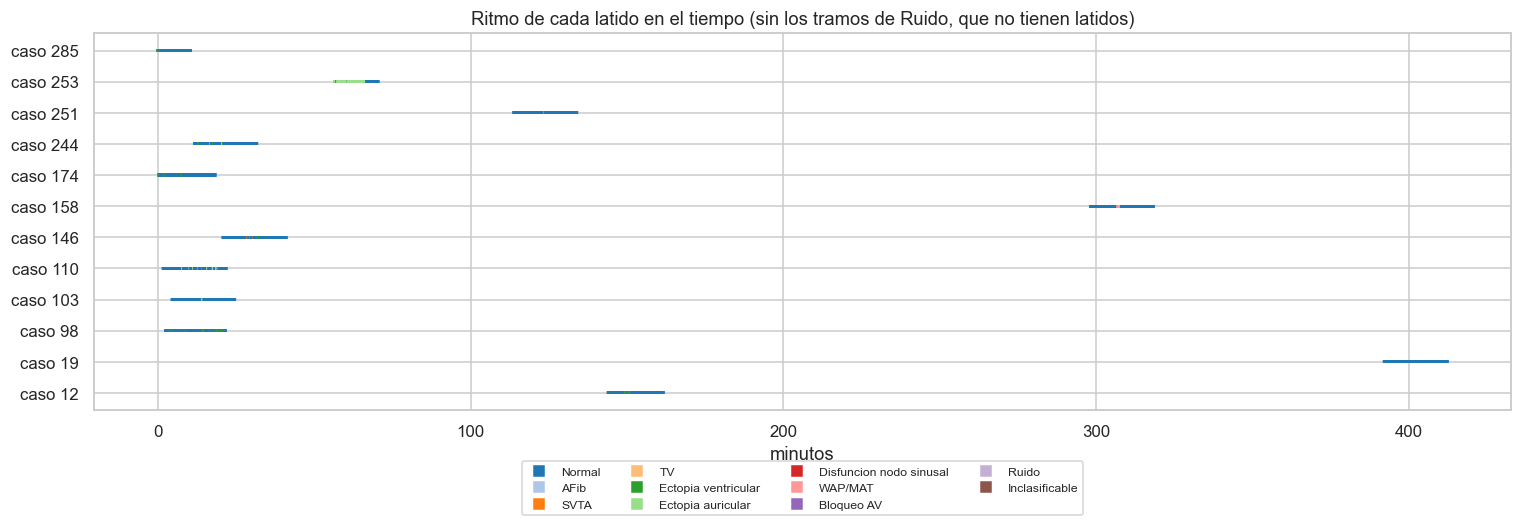

In [14]:
muestra = rit_por_caso[rit_por_caso >= 3].index[:12]
paleta = dict(zip(eu.CLASES_ORDEN, sns.color_palette("tab20", len(eu.CLASES_ORDEN))))
fig, ax = plt.subplots(figsize=(14, 5))
for i, cid in enumerate(muestra):
    g = ann[(ann.case_id == cid) & (ann.ritmo != "Ruido")]
    ax.scatter(g.time_second / 60, np.full(len(g), i), c=[paleta.get(r, "gray") for r in g.ritmo], s=4, marker="|")
ax.set_yticks(range(len(muestra))); ax.set_yticklabels([f"caso {c}" for c in muestra]); ax.set_xlabel("minutos")
ax.legend(handles=[plt.Line2D([], [], marker="s", ls="", color=c, label=k) for k, c in paleta.items()],
          ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.set_title("Ritmo de cada latido en el tiempo (sin los tramos de Ruido, que no tienen latidos)")
plt.tight_layout(); plt.savefig(FIGURAS / "eda_linea_tiempo.png"); plt.show()

**Interpretación.** Los segmentos de Normal, AFib, Disfunción del nodo sinusal o WAP/MAT duran desde decenas de segundos hasta minutos. La excepción son **TV y SVTA**: en estos datos un episodio dura en mediana entre 1.5 y 3 segundos (3 a 5 latidos). Por eso se usan ventanas de 10 s y una regla especial para esas dos clases (sección 8.1): con ventanas de 30 s casi desaparecían. Las transiciones entre ritmos generan ventanas mixtas, que se descartan con `PUREZA_MIN`.

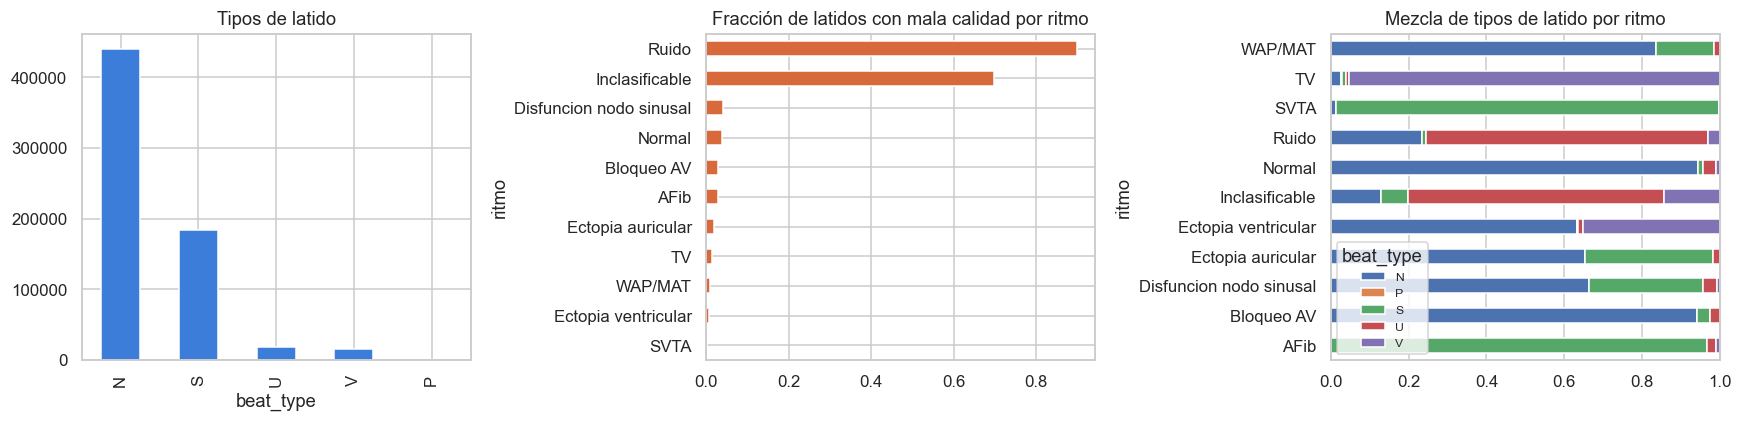

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ann.beat_type.value_counts().plot.bar(ax=ax[0], color="#3b7dd8"); ax[0].set_title("Tipos de latido")
(ann.groupby("ritmo").bad_signal_quality.mean().sort_values().plot.barh(ax=ax[1], color="#d8693b"))
ax[1].set_title("Fracción de latidos con mala calidad por ritmo")
pd.crosstab(ann.ritmo, ann.beat_type, normalize="index").plot.barh(stacked=True, ax=ax[2])
ax[2].set_title("Mezcla de tipos de latido por ritmo"); ax[2].legend(title="beat_type", fontsize=8)
plt.tight_layout(); plt.savefig(FIGURAS / "eda_calidad_latidos.png"); plt.show()

**Interpretación.** La mezcla de tipos de latido confirma que las etiquetas tienen sentido clínico: TV está formada casi solo por latidos ventriculares (V), SVTA y AFib por latidos supraventriculares (S), Ectopia ventricular combina N con una fracción grande de V y Ectopia auricular combina N con S. La mala calidad se concentra en Ruido (~90 %) e Inclasificable (~70 %); en el resto de ritmos es menor al 5 %, así que las arritmias no están contaminadas por ruido de forma sistemática. Recordatorio: `beat_type` **no entra como predictor** porque es una anotación humana.

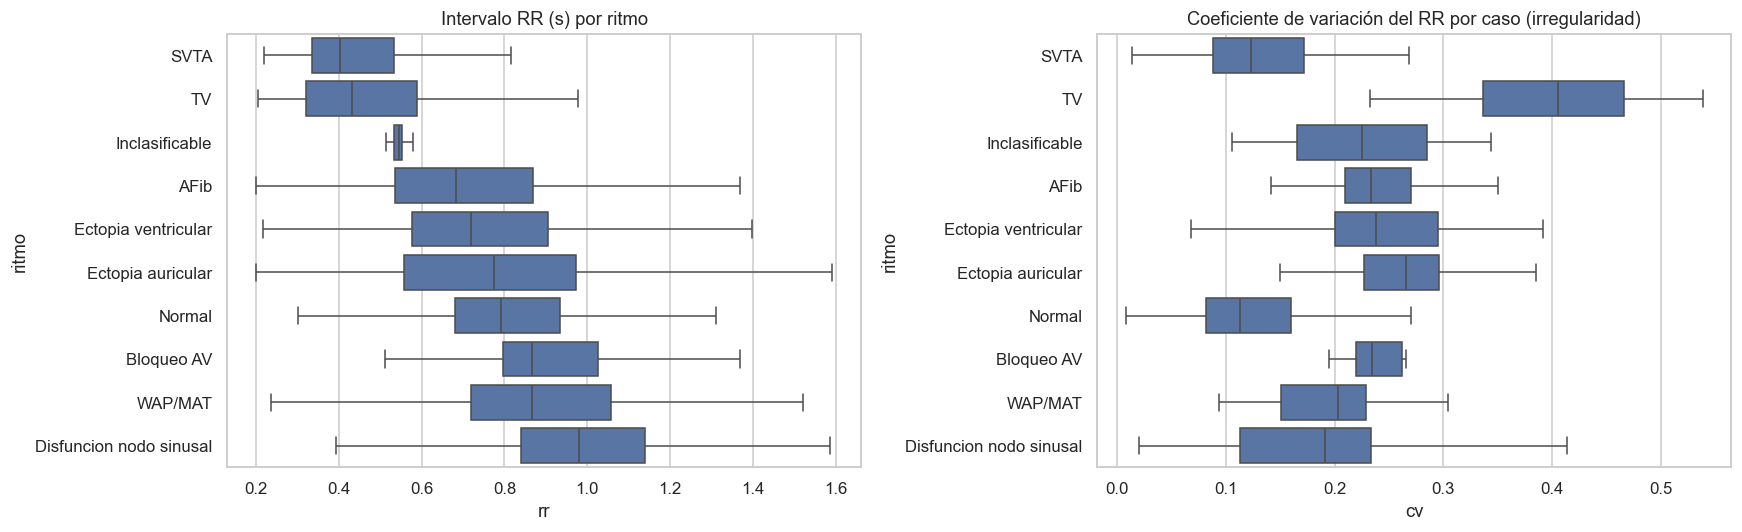

In [16]:
rr_filas = []
for cid, g in ann[ann.ritmo != "Ruido"].groupby("case_id"):
    t, r = g.time_second.values, g.ritmo.values
    rr = np.diff(t)
    ok = (rr > 0.2) & (rr < 3.0) & (r[:-1] == r[1:])
    rr_filas.append(pd.DataFrame({"case_id": cid, "ritmo": r[:-1][ok], "rr": rr[ok]}))
rr_df = pd.concat(rr_filas)
orden = rr_df.groupby("ritmo").rr.median().sort_values().index

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=rr_df.sample(min(len(rr_df), 200000), random_state=SEMILLA), y="ritmo", x="rr", order=orden, ax=ax[0], showfliers=False)
ax[0].set_title("Intervalo RR (s) por ritmo")
cv = rr_df.groupby(["ritmo", "case_id"]).rr.agg(lambda x: x.std() / x.mean() if len(x) > 20 else np.nan).dropna().reset_index(name="cv")
sns.boxplot(data=cv, y="ritmo", x="cv", order=orden, ax=ax[1], showfliers=False)
ax[1].set_title("Coeficiente de variación del RR por caso (irregularidad)")
plt.tight_layout(); plt.savefig(FIGURAS / "eda_rr_por_ritmo.png"); plt.show()

**Interpretación.** Contraste de hipótesis con los gráficos:

1. **TV y SVTA tienen los RR más cortos** (mediana ≈ 0.4 s, unos 150 lpm): confirmado, son taquicardias.
2. **Normal es el ritmo más regular** (coeficiente de variación ≈ 0.11, el más bajo) con RR cerca de 0.8 s: confirmado.
3. **AFib no es el más irregular**, al contrario de lo esperado: su variación (≈ 0.23) es similar a la de las ectopias (≈ 0.24 a 0.27). La diferencia es *cómo* es irregular: en AFib el desorden es continuo y sin patrón, en las ectopias hay un patrón corto-largo. Por eso se necesitan variables de patrón (`pnn20`, `pnn50`, `sampen`, `tpr`) y no solo de dispersión.
4. **TV muestra la variación más alta** (≈ 0.40), pero es un efecto de que sus episodios son muy cortos y alternan con latidos normales, no de un ritmo caótico.
5. **Disfunción del nodo sinusal y Bloqueo AV** tienen los RR más largos (bradicardia y pausas).

Las cajas que se solapan mucho (AFib, ectopias, Bloqueo AV, WAP/MAT en la variación del RR) anticipan confusión entre esas clases si solo se usa el RR.

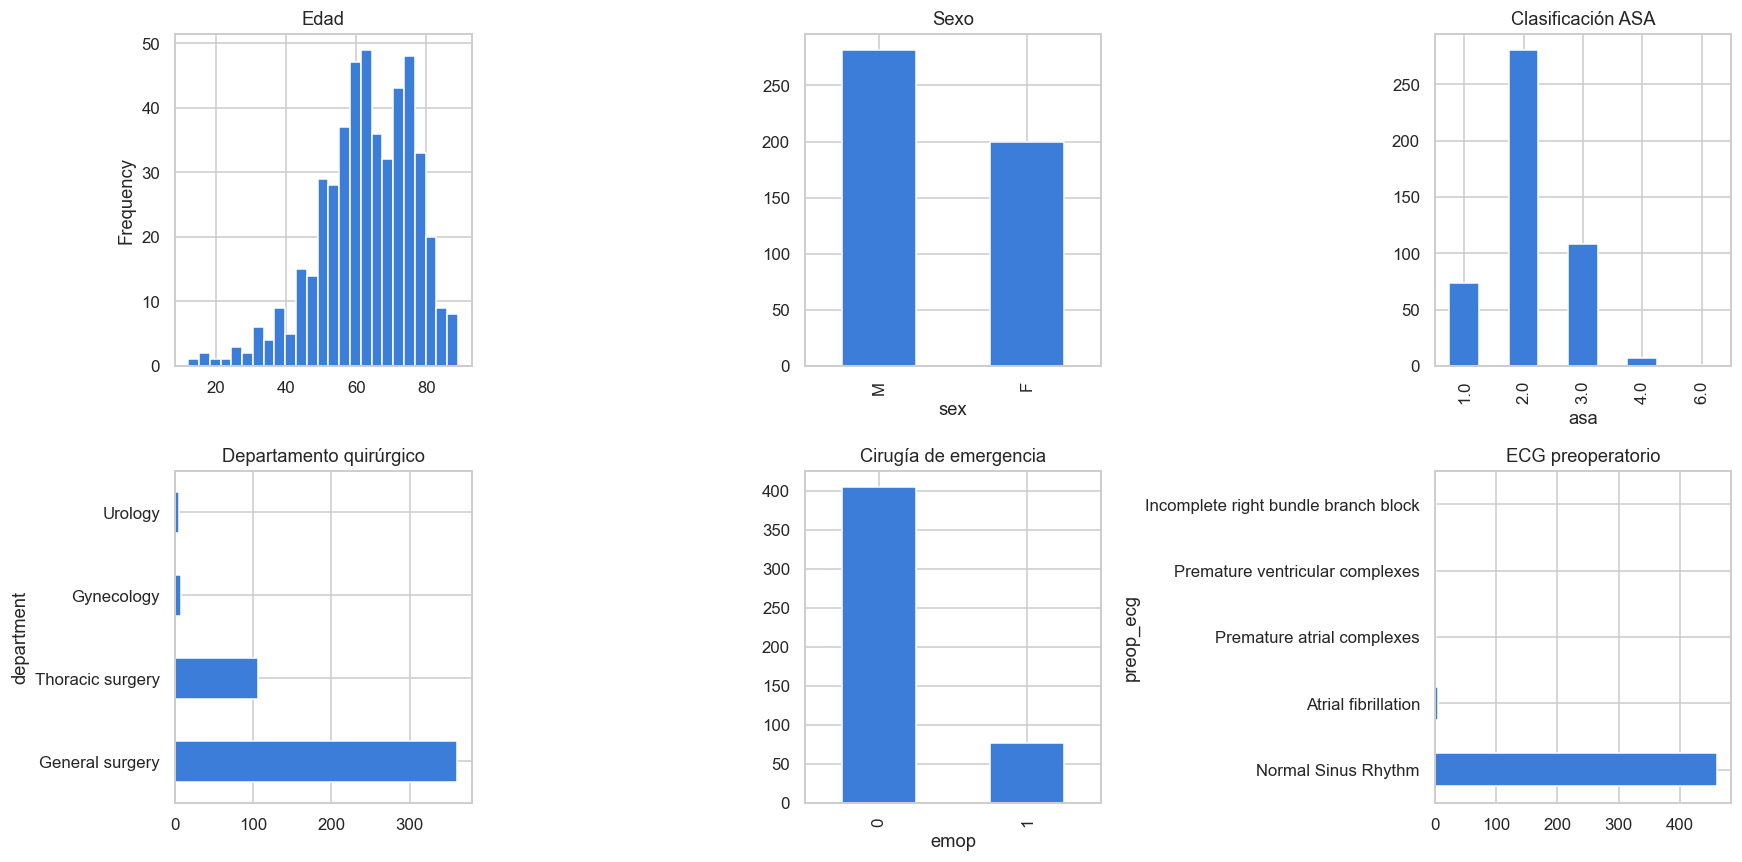

In [17]:
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
meta["age"].plot.hist(bins=25, ax=ax[0, 0], color="#3b7dd8"); ax[0, 0].set_title("Edad")
meta["sex"].value_counts().plot.bar(ax=ax[0, 1], color="#3b7dd8"); ax[0, 1].set_title("Sexo")
meta["asa"].value_counts().sort_index().plot.bar(ax=ax[0, 2], color="#3b7dd8"); ax[0, 2].set_title("Clasificación ASA")
meta["department"].value_counts().head(8).plot.barh(ax=ax[1, 0], color="#3b7dd8"); ax[1, 0].set_title("Departamento quirúrgico")
meta["emop"].value_counts().plot.bar(ax=ax[1, 1], color="#3b7dd8"); ax[1, 1].set_title("Cirugía de emergencia")
meta["preop_ecg"].value_counts().head(5).plot.barh(ax=ax[1, 2], color="#3b7dd8"); ax[1, 2].set_title("ECG preoperatorio")
plt.tight_layout(); plt.savefig(FIGURAS / "eda_demografia.png"); plt.show()

In [18]:
# ¿Los pacientes con cierta arritmia son distintos en edad o riesgo?
flags = pd.crosstab(ann.case_id, ann.ritmo).clip(upper=1).astype(bool)
m = meta.set_index("case_id").join(flags, how="inner")
filas = []
for r in flags.columns:
    if m[r].sum() >= 10:
        a, b = m.loc[m[r], "age"].dropna(), m.loc[~m[r], "age"].dropna()
        if len(a) > 5 and len(b) > 5:
            filas.append((r, int(m[r].sum()), a.mean(), b.mean(), stats.mannwhitneyu(a, b).pvalue))
tabla_edad = pd.DataFrame(filas, columns=["ritmo", "n_casos", "edad_con", "edad_sin", "p_mannwhitney"]).round(3)
tabla_edad["significativo_p<0.05"] = tabla_edad.p_mannwhitney < 0.05
display(tabla_edad.sort_values("p_mannwhitney"))

,ritmo,n_casos,edad_con,edad_sin,p_mannwhitney,significativo_p<0.05
0,AFib,111,68.207,61.526,0.000,True
5,Normal,370,61.595,67.920,0.000,True
8,TV,88,56.955,64.429,0.000,True
1,Bloqueo AV,10,53.400,63.269,0.051,False
3,Ectopia auricular,85,64.153,62.831,0.602,False
2,Disfuncion nodo sinusal,66,63.515,62.993,0.669,False
9,WAP/MAT,26,64.346,62.991,0.690,False
6,Ruido,250,63.036,63.095,0.746,False
7,SVTA,109,62.908,63.110,0.840,False
4,Ectopia ventricular,109,62.321,63.282,0.896,False


**Interpretación.** La población es de 482 pacientes de cirugía general (361) y torácica (107), con edad mediana de 64 años, 59 % hombres, mayoría ASA 2 y 16 % de cirugías de emergencia. El ECG preoperatorio es "ritmo sinusal normal" en 461 de 482 casos (96 %): las arritmias anotadas son en su gran mayoría **intraoperatorias**, no crónicas.

La edad sí difiere en tres ritmos (Mann-Whitney, p < 0.001): los pacientes con **AFib son mayores** (68 frente a 62 años), lo que concuerda con la epidemiología conocida, y los pacientes con **TV son más jóvenes** (57 frente a 64). Si se usaran metadatos, el modelo podría aprender "paciente mayor" en vez de "ritmo irregular". Esto confirma la decisión de **no usar metadatos clínicos** como predictores y obliga a declarar el sesgo poblacional (un hospital, población coreana, pacientes quirúrgicos).

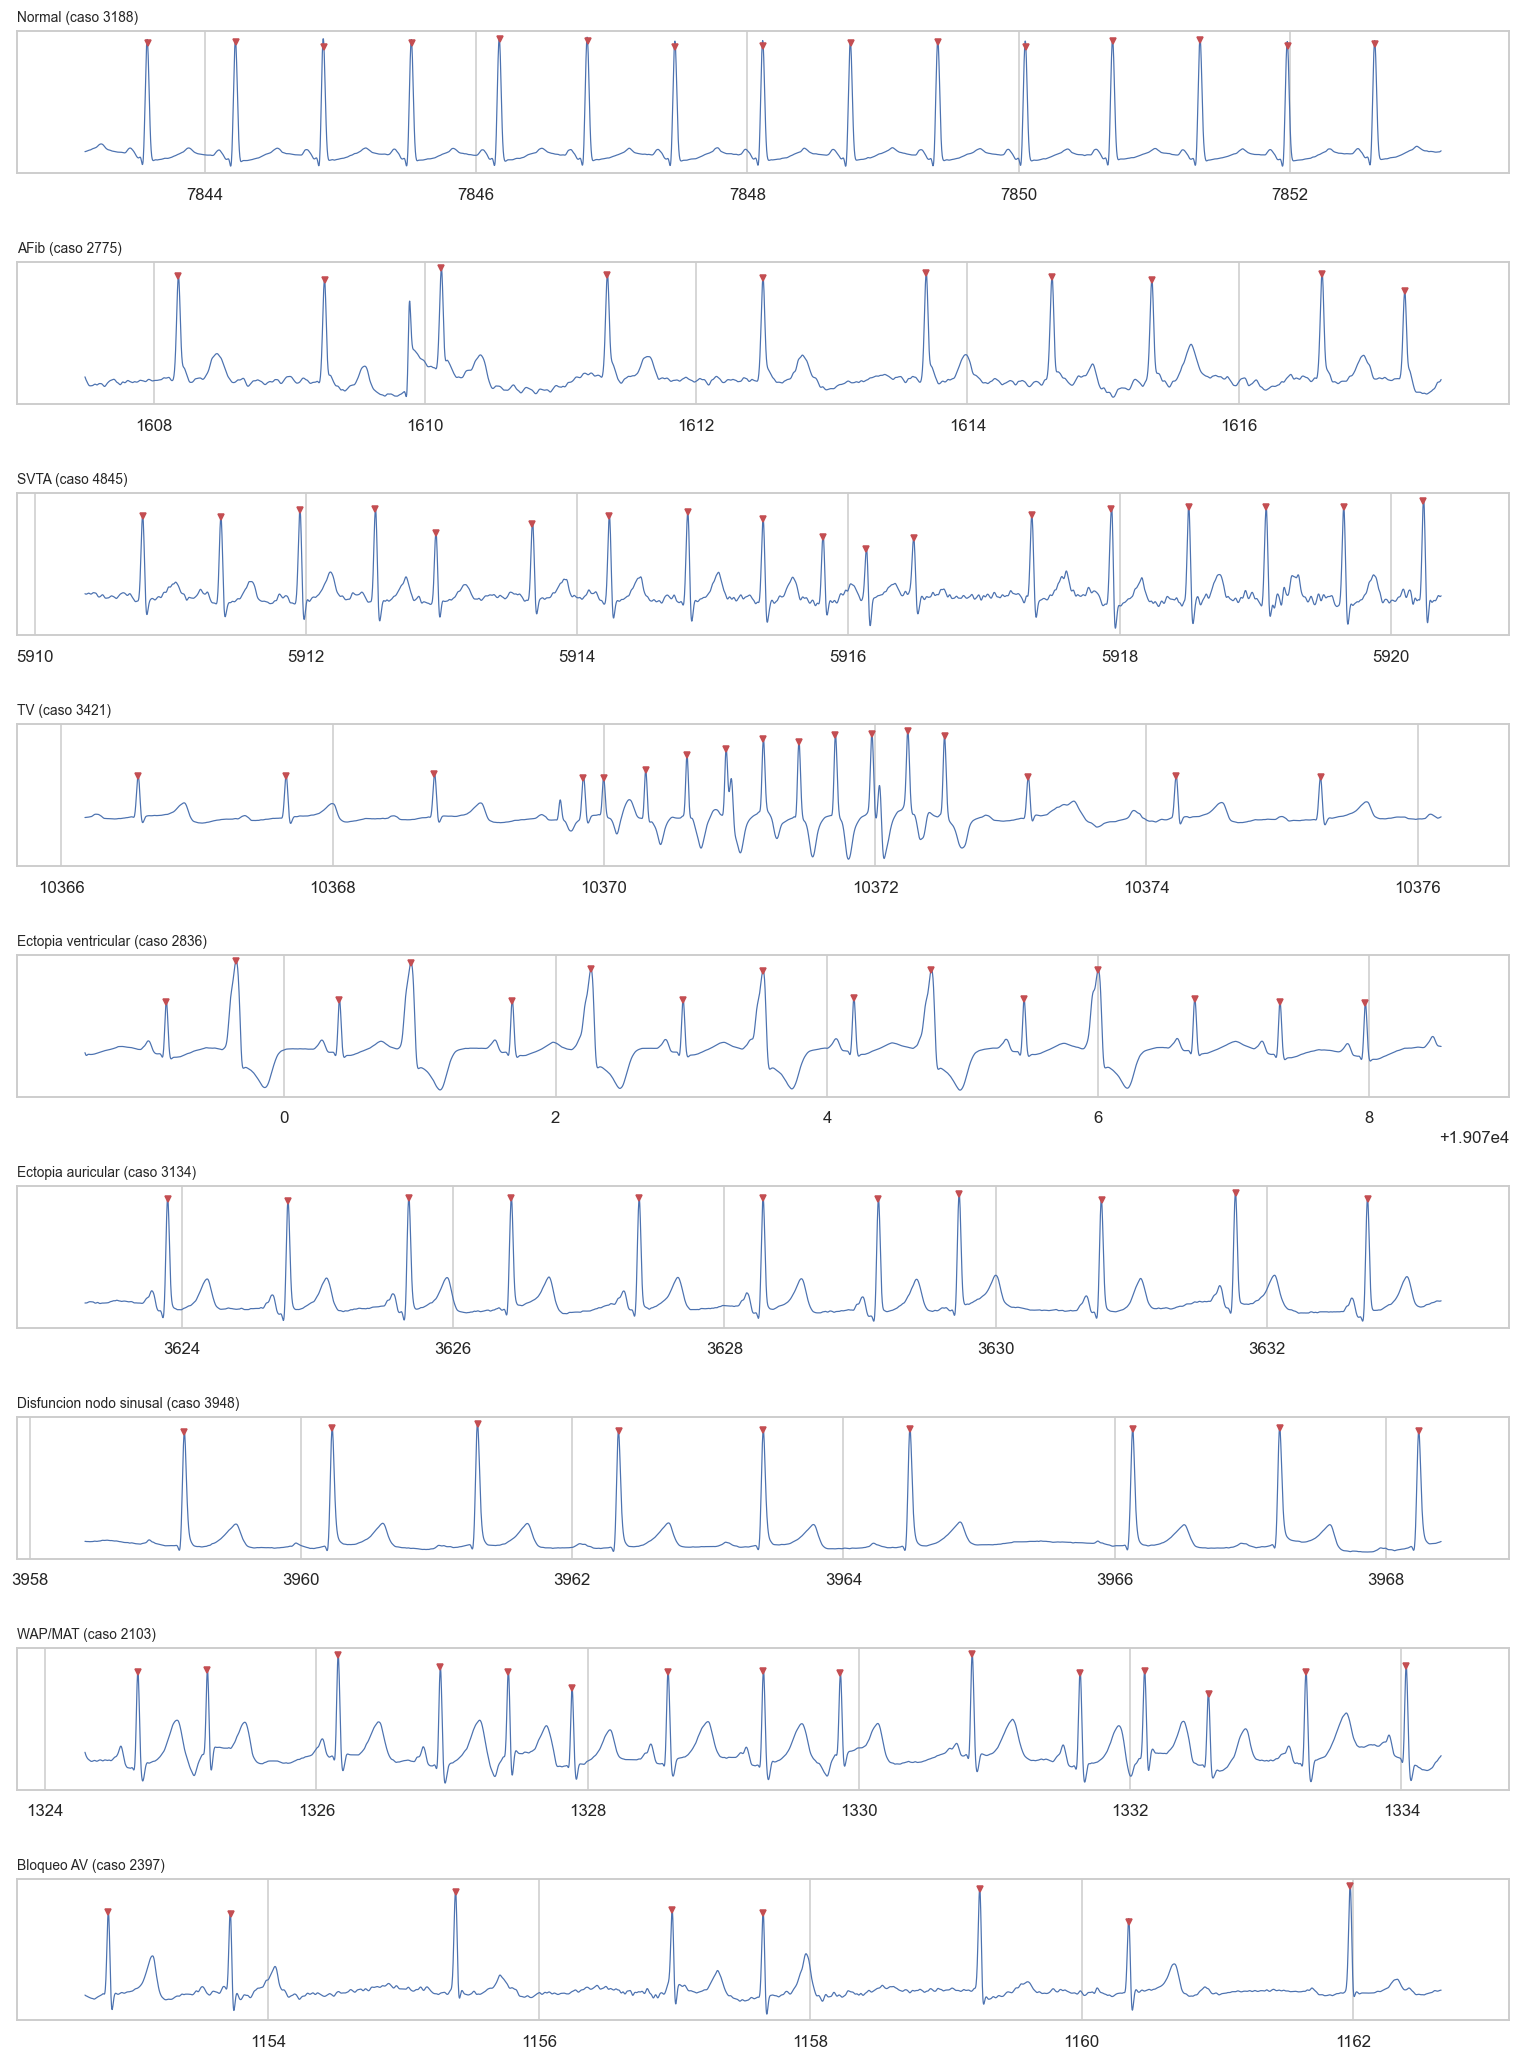

In [19]:
def ventana_ecg(cid, ini, dur=10):
    ecg, off = eu.cargar_ecg_cache(cid, ECG_DIR)
    if ecg is None:
        return None, None
    a, b = int((ini - off) * FS), int((ini + dur - off) * FS)
    if a < 0 or b > len(ecg):
        return None, None
    return ecg[a:b], np.arange(a, b) / FS + off

def ejemplo_por_ritmo(ritmo):
    g = ann[(ann.ritmo == ritmo) & ann.case_id.isin(casos_con_ecg)]
    if g.empty: return None
    cid = g.case_id.iloc[len(g) // 2]
    gg = g[g.case_id == cid]
    return cid, float(gg.time_second.iloc[len(gg) // 2] - 5)

ritmos_plot = [r for r in eu.CLASES_ORDEN if r not in ("Inclasificable", "Ruido") and ann.ritmo.eq(r).any()]
fig, axs = plt.subplots(len(ritmos_plot), 1, figsize=(14, 2.1 * len(ritmos_plot)))
axs = np.atleast_1d(axs)
for ax, r in zip(axs, ritmos_plot):
    ej = ejemplo_por_ritmo(r)
    x, t = ventana_ecg(*ej) if ej else (None, None)
    if x is None:
        ax.text(0.5, 0.5, f"{r}: sin ECG en caché", ha="center"); ax.axis("off"); continue
    ax.plot(t, eu.filtrar_ecg(x), lw=0.8)
    tp = ann[(ann.case_id == ej[0]) & (ann.time_second.between(t[0], t[-1]))].time_second
    ax.plot(tp, np.interp(tp, t, eu.filtrar_ecg(x)), "rv", ms=4)
    ax.set_title(f"{r} (caso {ej[0]})", fontsize=9, loc="left"); ax.set_yticks([])
plt.tight_layout(); plt.savefig(FIGURAS / "eda_ejemplos_ecg.png"); plt.show()

**Interpretación.** Los picos anotados (triángulos rojos) caen sobre los picos R, así que la alineación entre anotación y señal es correcta en estos ejemplos. Visualmente: Normal es perfectamente regular; AFib tiene intervalos irregulares sin onda P clara y con línea de base ondulante; SVTA es rápida y bastante regular; TV aparece como una salva de unos 8 latidos rápidos y anchos en medio de latidos normales (lo que confirma que los episodios son breves); Ectopia ventricular muestra un patrón alterno de latido normal y latido ancho y deformado (bigeminismo); Disfunción del nodo y Bloqueo AV muestran pausas largas. La anchura del QRS distingue TV y ectopia ventricular a simple vista, pero **no está entre nuestras características** (solo indirectamente vía `sig_sqi_qrs` y `sig_skew`).

---
# 7. Preprocesamiento de la señal ECG

Pasos aplicados a toda la señal, documentados para reproducibilidad (`src/ecg_utils.py`):

1. **Relleno de NaN** por interpolación lineal (los monitores dejan huecos al desconectar el electrodo).
2. **Filtro pasa banda Butterworth 0.5 a 40 Hz**, orden 3, de fase cero: quita deriva de la línea base (respiración, movimiento) y ruido de alta frecuencia (electrobisturí, red eléctrica).
3. **Detección de picos R** tipo Pan-Tompkins simplificado, con umbral adaptativo por bloques de 10 s.

La detección propia es clave para el despliegue: en producción **no hay anotaciones**, así que el sistema debe encontrar los picos solo. Aquí se valida el detector contra los picos anotados por los médicos.

       sensibilidad  precision
count        60.000     60.000
mean          0.963      0.925
std           0.134      0.157
min           0.000      0.000
25%           0.975      0.930
50%           0.996      0.981
75%           1.000      0.994
max           1.000      1.000

Casos con desfase mediano > 0.1 s (anotación desalineada de la señal):
 case_id  sensibilidad  precision  desfase_s
    1165           0.0        0.0     -0.251


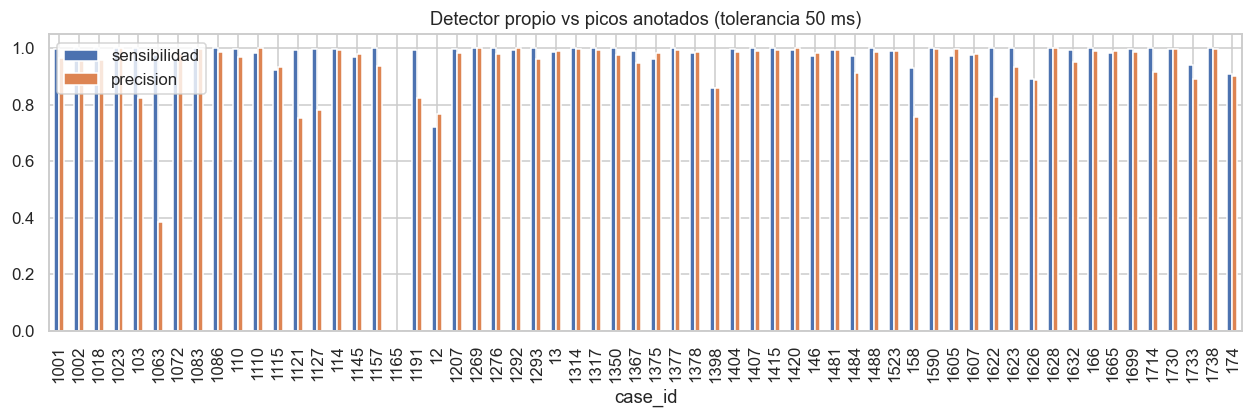

In [20]:
resultados = []
for cid in casos_con_ecg[:60]:
    ecg, off = eu.cargar_ecg_cache(cid, ECG_DIR)
    g = ann[(ann.case_id == cid) & (ann.ritmo != "Ruido") & (~ann.bad_signal_quality)]
    if g.empty: continue
    # tomar un tramo de 5 min limpio
    ini = g.time_second.iloc[0]; fin = ini + 300
    ref = g.time_second[(g.time_second >= ini) & (g.time_second < fin)].values - off
    a, b = int(round((ini - off) * FS)), int(round((fin - off) * FS))
    seg = ecg[a:b]
    det = eu.detectar_picos_r(seg, FS) + a / FS
    tp, fp, fn = eu.emparejar_picos(ref, det, tol=0.05)
    # Desfase mediano entre cada pico anotado y el detectado más cercano (detecta anotaciones desalineadas)
    desfase = np.nan
    if len(det) > 1 and len(ref):
        j = np.searchsorted(det, ref).clip(1, len(det) - 1)
        cercano = np.where(np.abs(det[j] - ref) < np.abs(det[j - 1] - ref), det[j], det[j - 1])
        desfase = float(np.median(cercano - ref))
    resultados.append((cid, tp, fp, fn, tp / max(tp + fn, 1), tp / max(tp + fp, 1), desfase))
det_df = pd.DataFrame(resultados, columns=["case_id", "TP", "FP", "FN", "sensibilidad", "precision", "desfase_s"])
if len(det_df):
    print(det_df[["sensibilidad", "precision"]].describe().round(3).to_string())
    print("\nCasos con desfase mediano > 0.1 s (anotación desalineada de la señal):")
    print(det_df.loc[det_df.desfase_s.abs() > 0.1, ["case_id", "sensibilidad", "precision", "desfase_s"]].round(3).to_string(index=False))
    det_df.set_index("case_id")[["sensibilidad", "precision"]].plot.bar(figsize=(14, 3.5), ylim=(0, 1.05))
    plt.title("Detector propio vs picos anotados (tolerancia 50 ms)"); plt.show()

**Interpretación.** En 60 casos, el detector propio tiene una mediana de sensibilidad de 0.996 y de precisión de 0.981; el 25 % peor sigue por encima de 0.93. Es suficiente para calcular intervalos RR en producción. La precisión media (0.925) es menor por algunos casos con falsos positivos (ondas T altas o ruido detectadas como latidos).

El caso **1165** tiene sensibilidad 0 con un desfase constante de −0.25 s: el detector sí encuentra los latidos, pero la anotación está corrida respecto a la señal. Es un problema del dato, no del detector, y conviene excluir ese caso de las características de señal en una siguiente iteración.

---
# 8. Construcción de ventanas y características

## 8.1 Ventaneo

Se corta cada caso en ventanas de `VENTANA_S` = 10 segundos. Ventanas más largas diluirían las arritmias breves: en estos datos la mediana de un episodio de TV o SVTA dura pocos segundos (3 a 5 latidos).

Cada tramo de ritmo va desde su primer latido hasta el primer latido del ritmo siguiente. La etiqueta de una ventana se asigna así:

1. **Salvas breves (TV, SVTA)**: si la ventana contiene al menos `EVENTOS_CORTOS` latidos (3) de ese ritmo, la ventana se etiqueta con él. Clínicamente equivale a "contiene una salva de 3 o más latidos".
2. **Resto de ritmos**: gana el ritmo que cubre más tiempo de la ventana, pero solo si cubre al menos `PUREZA_MIN` (80 %). Si no, la ventana es **mixta** y se descarta.
3. Las ventanas con ritmo necesitan al menos `MIN_LATIDOS` latidos. Las de **Ruido** no los necesitan, porque no tienen latidos.
4. Se guarda el `case_id` de cada ventana para poder particionar por paciente.

## 8.2 Características

| Grupo | Variables | Qué captura |
|---|---|---|
| Frecuencia | `fc_media`, `fc_pico` (máxima sostenida en 3 latidos), `rr_media`, `rr_mediana`, `rr_min`, `rr_max` | Taquicardia, bradicardia, pausas |
| Variabilidad | `sdnn`, `rmssd`, `pnn50`, `pnn20`, `cv_rr`, `rr_iqr`, `rr_mad` | Irregularidad global (AFib) |
| Geometría | `sd1`, `sd2`, `sd1_sd2` (Poincaré) | Forma de la nube RR(n) vs RR(n+1) |
| Patrón | `frac_rr_corto`, `frac_rr_largo`, `tpr`, `sampen`, `rr_skew`, `rr_kurt` | Ectopias (corto-largo), aleatoriedad |
| Señal | `sig_std`, `sig_p2p`, `sig_skew`, `sig_kurt`, `sig_sqi_qrs`, `sig_ruido_alto`, `sig_deriva`, `sig_frac_plana` | Calidad: distingue Ruido |

In [21]:
def ventanas_de_un_caso(cid, g, fuente, usar_senal):
    # Construir las ventanas de un caso (g = filas de anotación del caso, ordenadas por tiempo)
    ecg, off = eu.cargar_ecg_cache(cid, ECG_DIR) if (usar_senal or fuente == "detectados") else (None, None)
    if (usar_senal or fuente == "detectados") and ecg is None:
        return []
    t, rit, mala = g.time_second.values, g.ritmo.values, g.bad_signal_quality.values
    # Tramos de ritmo: desde el primer latido de cada cambio hasta el primer latido del siguiente
    cambio = np.r_[True, rit[1:] != rit[:-1]]
    seg_ini, seg_rit = t[cambio], rit[cambio]
    seg_fin = np.r_[seg_ini[1:], t[-1]]
    filas = []
    for ini in np.arange(np.floor(t.min()), t.max() - VENTANA_S + 1e-9, PASO_S):
        fin = ini + VENTANA_S
        m = (t >= ini) & (t < fin)
        if not m.any():
            continue
        # Segundos de la ventana cubiertos por cada ritmo
        solape = np.clip(np.minimum(seg_fin, fin) - np.maximum(seg_ini, ini), 0, None)
        cobertura = pd.Series(solape).groupby(seg_rit).sum() / VENTANA_S
        # Latidos reales (sin las filas de ruido) por ritmo dentro de la ventana
        lat_m = m & (rit != "Ruido")
        n_por_ritmo = pd.Series(rit[lat_m]).value_counts()
        etiqueta = next((r for r, n in EVENTOS_CORTOS.items() if n_por_ritmo.get(r, 0) >= n), None)
        if etiqueta is not None:
            pureza = float(n_por_ritmo[etiqueta] / max(n_por_ritmo.sum(), 1))
        else:
            etiqueta, pureza = cobertura.idxmax(), float(cobertura.max())
            if pureza < PUREZA_MIN:
                continue          # ventana mixta
            if etiqueta != "Ruido" and lat_m.sum() < MIN_LATIDOS:
                continue
        x = None
        if ecg is not None:
            a, b = int(round((ini - off) * FS)), int(round((fin - off) * FS))
            if a >= 0 and b <= len(ecg):
                x = ecg[a:b]
        if usar_senal and x is None:
            continue
        picos = eu.detectar_picos_r(x, FS) if fuente == "detectados" else t[lat_m] - ini
        f = eu.features_ventana(picos, x if usar_senal else None, FS)
        f.update(case_id=cid, t_ini=ini, etiqueta=etiqueta, pureza=pureza, frac_mala_calidad=float(mala[m].mean()))
        filas.append(f)
    return filas

def construir_ventanas(ann, fuente=FUENTE_PICOS, usar_senal=USAR_SENAL):
    from joblib import Parallel, delayed
    grupos_ann = [(cid, g) for cid, g in ann.groupby("case_id")]
    partes = Parallel(n_jobs=-1)(delayed(ventanas_de_un_caso)(cid, g, fuente, usar_senal) for cid, g in grupos_ann)
    return pd.DataFrame([f for p in partes for f in p])

t0 = time.time()
ventanas = construir_ventanas(ann)
print(f"{len(ventanas)} ventanas de {ventanas.case_id.nunique()} casos en {time.time()-t0:.0f}s")
ventanas.etiqueta.value_counts()

50573 ventanas de 482 casos en 46s


etiqueta
Normal                     31432
AFib                       11761
Disfuncion nodo sinusal     2181
Ectopia ventricular         1493
Ectopia auricular           1300
WAP/MAT                      867
SVTA                         481
Ruido                        419
Bloqueo AV                   389
TV                           242
Inclasificable                 8
Name: count, dtype: int64

### Interpretación

Se construyeron 50,573 ventanas de 10 s de los 482 casos. Normal (31,432) y AFib (11,761) suman el 85 %. Las clases breves quedan con pocas ventanas pero en **muchos pacientes**: TV 242 ventanas en 87 pacientes y SVTA 481 en 106, lo cual es bueno para evaluar por paciente. Ruido queda con 419 ventanas (107 pacientes): muchos tramos de ruido duran menos que una ventana o se mezclan con otros ritmos. En cambio, **Bloqueo AV (389 ventanas) y WAP/MAT (867) vienen de muy pocos pacientes (10 y 23)**: el modelo verá esas clases en pocos individuos y será difícil que generalicen.

In [22]:
cuentas = ventanas.groupby("etiqueta").agg(ventanas=("case_id", "size"), pacientes=("case_id", "nunique"))
display(cuentas.sort_values("ventanas"))

# Regla: se descartan las clases con pocas ventanas o muy pocos pacientes (no se pueden evaluar por paciente)
descartar = cuentas[(cuentas.ventanas < CLASES_MIN_VENTANAS) | (cuentas.pacientes < 8)].index.tolist()
print("Clases descartadas:", descartar)
datos = ventanas[~ventanas.etiqueta.isin(descartar)]
# Tope por clase: Normal y AFib tienen decenas de miles de ventanas y harían muy lentos los modelos (SVM sobre todo).
# El submuestreo es aleatorio y conserva todos los casos; las clases raras quedan completas.
if MAX_POR_CLASE:
    datos = pd.concat([d.sample(min(len(d), MAX_POR_CLASE), random_state=SEMILLA) for _, d in datos.groupby("etiqueta")])
datos = datos.reset_index(drop=True)
COLS = [c for c in eu.NOMBRES_RR + eu.NOMBRES_SENAL if c in datos.columns and datos[c].notna().any()]
if not USAR_SENAL:
    COLS = [c for c in COLS if not c.startswith("sig_")]
print(f"{len(datos)} ventanas, {len(COLS)} características, {datos.etiqueta.nunique()} clases")
datos.etiqueta.value_counts()

,ventanas,pacientes
etiqueta,,
Inclasificable,8,2
TV,242,87
Bloqueo AV,389,10
Ruido,419,107
SVTA,481,106
WAP/MAT,867,23
Ectopia auricular,1300,71
Ectopia ventricular,1493,92
Disfuncion nodo sinusal,2181,59


Clases descartadas: ['Inclasificable']
17372 ventanas, 31 características, 10 clases


etiqueta
AFib                       5000
Normal                     5000
Disfuncion nodo sinusal    2181
Ectopia ventricular        1493
Ectopia auricular          1300
WAP/MAT                     867
SVTA                        481
Ruido                       419
Bloqueo AV                  389
TV                          242
Name: count, dtype: int64

**Interpretación.** Solo se descartó Inclasificable (8 ventanas, 2 pacientes). Bloqueo AV se mantuvo porque supera los umbrales (389 ventanas, 10 pacientes), pero está en el límite. El tope `MAX_POR_CLASE` dejó Normal y AFib en 5,000 ventanas cada una; el conjunto de trabajo tiene 17,372 ventanas, 31 características y 10 clases. Con el tope, la distribución ya no es la real: sirve para comparar modelos y entrenar, pero **la precisión por clase en producción será menor** para las arritmias, porque allí su prevalencia es mucho más baja.

Nulos por característica (%):
sampen        61.7
sd1_sd2        5.0
fc_media       2.4
sdnn           2.4
rr_mediana     2.4
fc_pico        2.4
rr_media       2.4
rr_max         2.4
pnn20          2.4
cv_rr          2.4


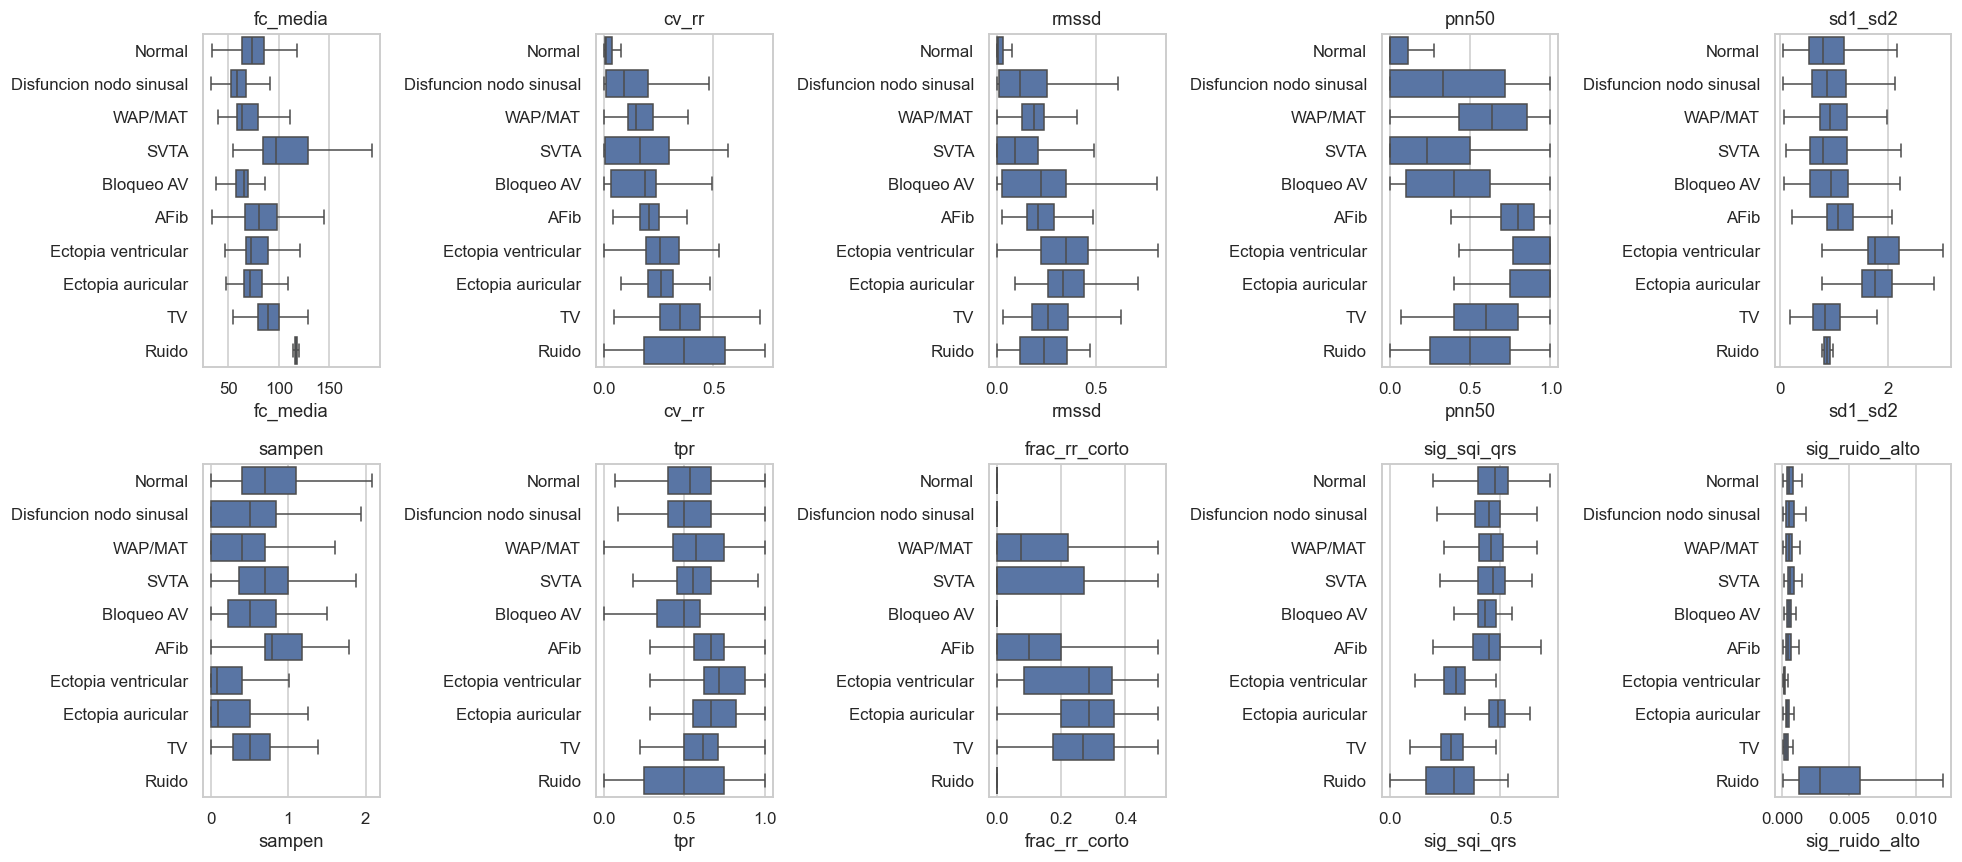

In [23]:
print("Nulos por característica (%):")
print((datos[COLS].isna().mean() * 100).round(1).sort_values(ascending=False).head(10).to_string())

orden_cl = datos.groupby("etiqueta").cv_rr.median().sort_values().index
sel = [c for c in ["fc_media", "cv_rr", "rmssd", "pnn50", "sd1_sd2", "sampen", "tpr", "frac_rr_corto"] + (["sig_sqi_qrs", "sig_ruido_alto"] if USAR_SENAL else []) if c in COLS]
fig, axs = plt.subplots(2, (len(sel) + 1) // 2, figsize=(18, 8))
for ax, c in zip(axs.ravel(), sel):
    sns.boxplot(data=datos, y="etiqueta", x=c, order=orden_cl, ax=ax, showfliers=False)
    ax.set_title(c); ax.set_ylabel("")
plt.tight_layout(); plt.savefig(FIGURAS / "eda_features_por_clase.png"); plt.show()

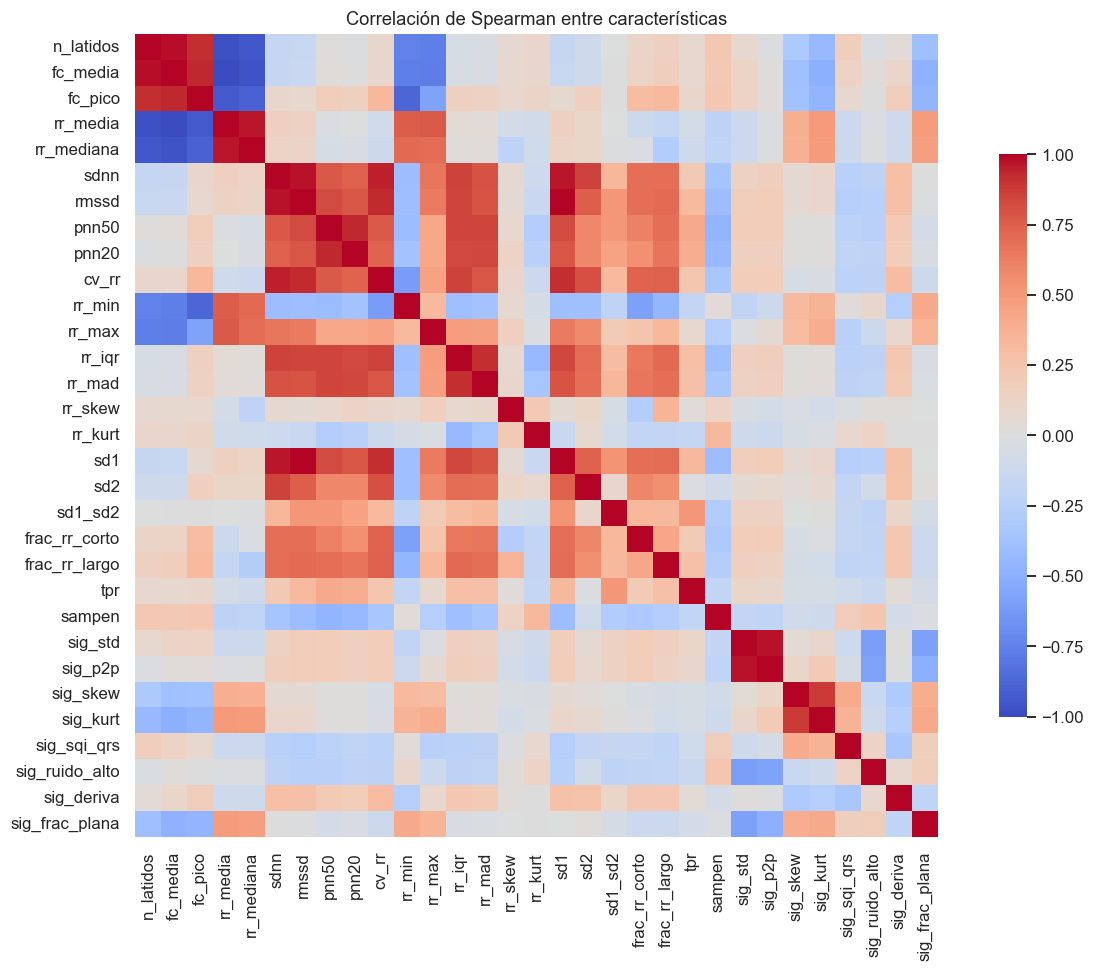

,var_a,var_b,rho
0,n_latidos,fc_media,0.983
1,n_latidos,rr_media,-0.983
2,fc_media,rr_media,-1.000
3,fc_media,rr_mediana,-0.963
4,rr_media,rr_mediana,0.963
5,sdnn,rmssd,0.970
6,sdnn,sd1,0.967
7,rmssd,sd1,0.999
8,sig_std,sig_p2p,0.969


In [24]:
corr = datos[COLS].corr(method="spearman")
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Correlación de Spearman entre características"); plt.tight_layout()
plt.savefig(FIGURAS / "eda_correlacion.png"); plt.show()

# Pares casi redundantes (|rho| > 0.95)
pares = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(COLS) for b in COLS[i+1:] if abs(corr.loc[a, b]) > 0.95]
pd.DataFrame(pares, columns=["var_a", "var_b", "rho"])

**Interpretación.**

- **Nulos**: `sampen` falta en el 62 % de las ventanas porque la entropía muestral necesita más latidos de los que caben en 10 s; aporta poco y es candidata a eliminarse o a calcularse con otra parametrización. El resto de variables de RR falta en ~2.4 % (ventanas de Ruido sin latidos).
- **Separación por clase**: `fc_media` separa las taquicardias (SVTA) de las bradicardias (Disfunción del nodo, Bloqueo AV); `cv_rr`, `rmssd` y `pnn50` separan Normal (muy bajo) del resto; `sd1_sd2` y `frac_rr_corto` destacan en las **ectopias** (patrón corto-largo); `sig_sqi_qrs` es más bajo en **TV y Ectopia ventricular** (QRS ancho, menos energía en 5-15 Hz) y en Ruido; `sig_ruido_alto` es alto solo en Ruido.
- **Redundancia**: hay pares casi idénticos (`fc_media` y `rr_media` ρ = −1.00; `rmssd` y `sd1` 0.999; `sdnn` y `rmssd` 0.97; `n_latidos` y `fc_media` 0.98). No dañan a los árboles, pero sí a la regresión logística y al SVM, y reparten la importancia en SHAP. Se pueden eliminar en una siguiente iteración.

---
# 9. Exploración no supervisada

Aunque el problema es supervisado, PCA y K-Means ayudan a (i) ver si las clases forman estructura natural, (ii) encontrar ventanas atípicas o mal etiquetadas, y (iii) entender si el ruido se separa.

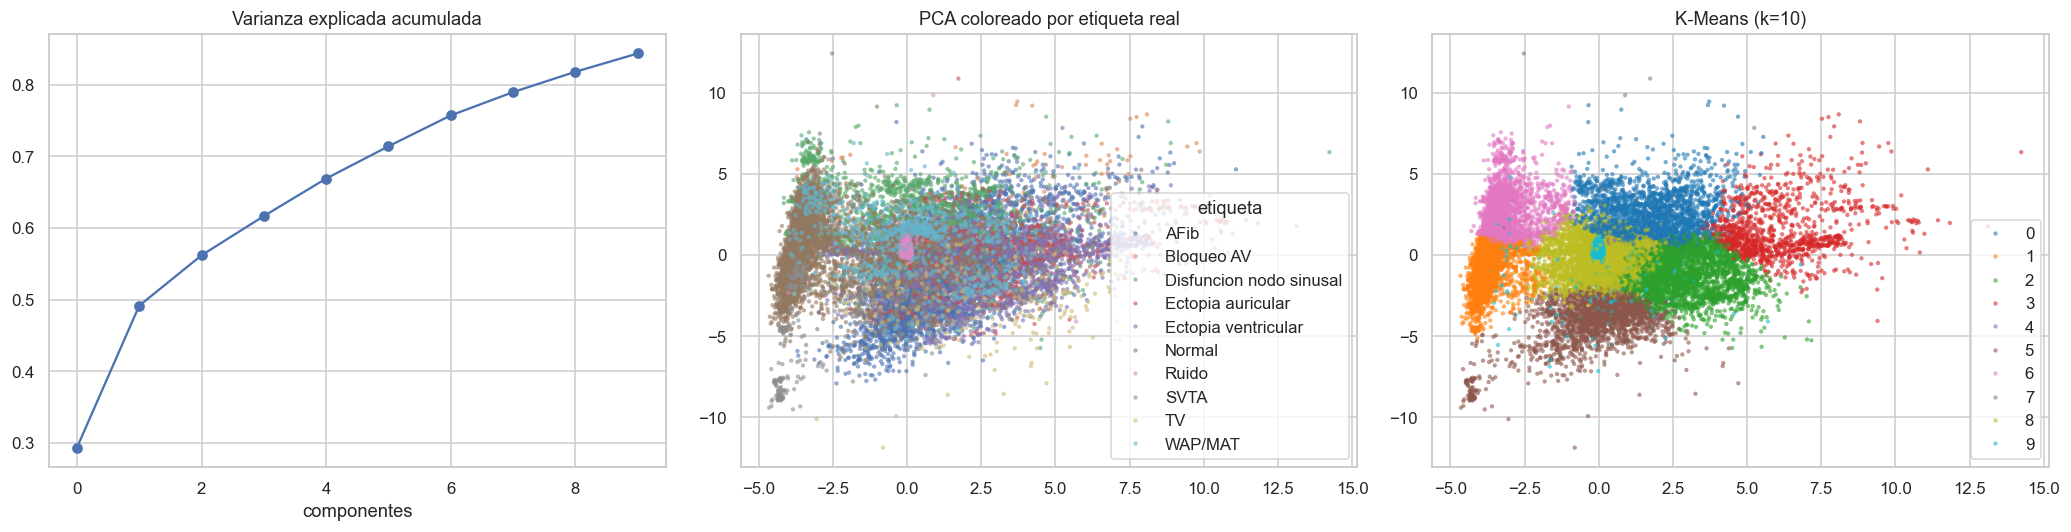

ARI (K-Means vs etiqueta): 0.199
Silhouette: 0.152


col_0,0,1,2,3,4,5,6,7,8,9
etiqueta,,,,,,,,,,
AFib,952,4,1068,289,1,1509,7,0,1102,68
Bloqueo AV,144,60,4,32,0,0,74,0,73,2
Disfuncion nodo sinusal,660,149,107,73,0,5,847,0,320,20
Ectopia auricular,99,3,483,317,0,89,0,1,303,5
Ectopia ventricular,78,50,642,355,0,130,39,1,191,7
Normal,92,2324,91,27,2,104,1684,1,579,96
Ruido,0,1,0,0,9,0,0,6,9,394
SVTA,1,111,95,7,0,201,1,0,62,3
TV,1,2,109,22,0,70,0,0,36,2


In [25]:
Xs = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]).fit_transform(datos[COLS])
pca = PCA(n_components=min(10, len(COLS)), random_state=SEMILLA).fit(Xs)
Z = pca.transform(Xs)

fig, ax = plt.subplots(1, 3, figsize=(19, 5))
ax[0].plot(np.cumsum(pca.explained_variance_ratio_), "o-"); ax[0].set_title("Varianza explicada acumulada"); ax[0].set_xlabel("componentes")
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=datos.etiqueta, s=8, alpha=.6, ax=ax[1], linewidth=0); ax[1].set_title("PCA coloreado por etiqueta real")
k = datos.etiqueta.nunique()
km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Xs)
sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=km.labels_, palette="tab10", s=8, alpha=.6, ax=ax[2], linewidth=0); ax[2].set_title(f"K-Means (k={k})")
plt.tight_layout(); plt.savefig(FIGURAS / "no_supervisado_pca.png"); plt.show()

from sklearn.metrics import adjusted_rand_score, silhouette_score
print("ARI (K-Means vs etiqueta):", round(adjusted_rand_score(datos.etiqueta, km.labels_), 3))
print("Silhouette:", round(silhouette_score(Xs, km.labels_, sample_size=min(5000, len(Xs)), random_state=SEMILLA), 3))
display(pd.crosstab(datos.etiqueta, km.labels_))

**Interpretación.** Las 10 primeras componentes explican ~84 % de la varianza (la primera, 29 %). En el PCA las clases se superponen mucho y K-Means con k = 10 apenas recupera las etiquetas (ARI = 0.20, silueta = 0.15): **las clases no forman grupos naturales**, lo que justifica el enfoque supervisado. La excepción es **Ruido**, que cae casi entero en un mismo cluster (394 de 419 ventanas en el grupo 9), y Normal se reparte en dos grupos. AFib, ectopias y WAP/MAT se mezclan en los mismos clusters, anticipando las confusiones del modelo.

---
# 10. Partición por paciente

## Por qué no se puede usar un `train_test_split` aleatorio

Las ventanas de un mismo paciente son muy parecidas entre sí (misma morfología de ECG, mismo electrodo, misma anestesia). Si ventanas del paciente A caen en train y test, el modelo puede **memorizar al paciente** y la métrica de test saldría inflada: es **fuga de datos**. La regla es que **un paciente solo puede estar en un lado**.

Además hay desbalance, así que se usa `StratifiedGroupKFold`: agrupa por paciente y trata de mantener las proporciones de clase en cada pliegue.

Esquema:

- **Test final** (~20 % de los pacientes): se toca **una sola vez**, al final.
- **Train** (~80 %): aquí se hace validación cruzada agrupada para elegir modelo e hiperparámetros.

In [26]:
X = datos[COLS].copy()
y = datos["etiqueta"].copy()
grupos = datos["case_id"].copy()

# 5 pliegues agrupados; el primero se reserva como TEST FINAL (~20% de pacientes)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
idx_train, idx_test = next(sgkf.split(X, y, grupos))
X_tr, y_tr, g_tr = X.iloc[idx_train], y.iloc[idx_train], grupos.iloc[idx_train]
X_te, y_te, g_te = X.iloc[idx_test], y.iloc[idx_test], grupos.iloc[idx_test]

assert set(g_tr).isdisjoint(set(g_te)), "FUGA: hay pacientes en train y test"
print(f"Train: {len(X_tr)} ventanas / {g_tr.nunique()} pacientes | Test: {len(X_te)} ventanas / {g_te.nunique()} pacientes")
comp = pd.concat([y_tr.value_counts(normalize=True).rename("train"), y_te.value_counts(normalize=True).rename("test")], axis=1).round(3)
comp

Train: 13930 ventanas / 388 pacientes | Test: 3442 ventanas / 94 pacientes


,train,test
etiqueta,,
AFib,0.287,0.289
Normal,0.287,0.290
Disfuncion nodo sinusal,0.125,0.127
Ectopia ventricular,0.086,0.087
Ectopia auricular,0.075,0.076
WAP/MAT,0.050,0.050
SVTA,0.028,0.028
Ruido,0.024,0.024
Bloqueo AV,0.024,0.016


**Interpretación.** La aserción confirma que ningún paciente está en train y test a la vez: 388 pacientes y 13,930 ventanas para entrenar, 94 pacientes y 3,442 ventanas para test. Las proporciones de clase son prácticamente iguales en ambos lados (diferencias de 0.1 puntos), salvo Bloqueo AV (2.4 % frente a 1.6 %), algo esperable con solo 10 pacientes. Con clases de pocos pacientes, la métrica de test es **ruidosa**; por eso se reporta también la validación cruzada por paciente.

---
# 11. Modelado y selección de hiperparámetros

## 11.1 Estrategia

1. **Línea base trivial** (siempre la clase mayoritaria) para saber qué es "no aprender nada".
2. **Cuatro familias de modelo**, cada una con su razón de ser:

| Modelo | Por qué probarlo |
|---|---|
| Regresión logística | Línea base lineal interpretable |
| Random Forest | Robusto, no necesita escalar, maneja no linealidad y redundancia |
| HistGradientBoosting | Suele ser el mejor en tabular; maneja NaN de forma nativa |
| SVM con kernel RBF | Frontera no lineal suave; sensible a escala y a `C`, `gamma` |

3. **Imputación** con la mediana y **escalado** dentro de un `Pipeline`, para que se ajusten solo con train de cada pliegue (evita fuga de preprocesamiento).
4. **Desbalance**: `class_weight="balanced"` en vez de remuestrear. Es simple y no crea ventanas sintéticas que contaminen la validación.
5. **Métrica de selección: F1 macro.** Promedia el F1 de cada clase con el mismo peso, así las clases raras (TV, ectopias) cuentan tanto como Normal.
6. **Validación**: `StratifiedGroupKFold` de 5 pliegues sobre train.

In [27]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

def pipe(clf, escalar=True):
    pasos = [("imp", SimpleImputer(strategy="median"))]
    if escalar:
        pasos.append(("sc", StandardScaler()))
    return Pipeline(pasos + [("clf", clf)])

modelos = {
    "Regresión logística": pipe(LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEMILLA)),
    "Random Forest": pipe(RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", n_jobs=-1, random_state=SEMILLA), escalar=False),
    "HistGradientBoosting": Pipeline([("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=SEMILLA))]),
    "SVM RBF": pipe(SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEMILLA)),
}

# línea base trivial: clase mayoritaria
mayoritaria = y_tr.value_counts().idxmax()
print(f"Línea base trivial (siempre '{mayoritaria}'): F1 macro =",
      round(f1_score(y_tr, np.full(len(y_tr), mayoritaria), average="macro"), 3))

scoring = {"f1_macro": "f1_macro", "bal_acc": "balanced_accuracy", "acc": "accuracy"}
res = {}
for nombre, m in modelos.items():
    t0 = time.time()
    r = cross_validate(m, X_tr, y_tr, groups=g_tr, cv=cv, scoring=scoring, return_train_score=True, n_jobs=1)
    res[nombre] = {"F1 macro (val)": r["test_f1_macro"].mean(), "± F1": r["test_f1_macro"].std(),
                   "F1 macro (train)": r["train_f1_macro"].mean(), "Bal. acc (val)": r["test_bal_acc"].mean(),
                   "Exactitud (val)": r["test_acc"].mean(), "seg": time.time() - t0}
tabla_cv = pd.DataFrame(res).T.round(3)
tabla_cv.sort_values("F1 macro (val)", ascending=False)

Línea base trivial (siempre 'AFib'): F1 macro = 0.045


,F1 macro (val),± F1,F1 macro (train),Bal. acc (val),Exactitud (val),seg
SVM RBF,0.556,0.059,0.765,0.606,0.654,160.061
HistGradientBoosting,0.551,0.043,0.981,0.560,0.695,29.961
Regresión logística,0.529,0.055,0.636,0.592,0.603,3.737
Random Forest,0.527,0.044,1.000,0.512,0.704,10.484


**Interpretación.**

- Todos los modelos superan con amplitud la línea base trivial (F1 macro 0.045): aprenden algo real.
- Los cuatro quedan muy cerca entre sí en validación por paciente (0.53 a 0.56). El **SVM** es el mejor sin afinar (0.556) y el más estable en exactitud balanceada (0.606), pero tarda 160 s; **HistGradientBoosting** está prácticamente empatado (0.551) y es cinco veces más rápido.
- La brecha train-validación es grande en los árboles (Random Forest 1.00 frente a 0.53; HistGradientBoosting 0.98 frente a 0.55): memorizan el entrenamiento. La regresión logística y el SVM tienen brechas menores (0.64 / 0.53 y 0.77 / 0.56).
- La exactitud (0.60 a 0.70) es mayor que el F1 macro porque Normal y AFib, las clases más grandes, se aciertan mejor que las raras.
- Que modelos tan distintos lleguen al mismo techo sugiere que **el límite está en las características, no en el algoritmo**.

In [28]:
from scipy.stats import loguniform, randint, uniform

espacios = {
    "Random Forest": {
        "clf__n_estimators": randint(200, 600), "clf__max_depth": [None, 8, 12, 20],
        "clf__min_samples_leaf": randint(1, 10), "clf__max_features": ["sqrt", "log2", 0.5],
    },
    "HistGradientBoosting": {
        "clf__learning_rate": loguniform(0.02, 0.3), "clf__max_iter": randint(150, 500),
        "clf__max_leaf_nodes": randint(8, 64), "clf__min_samples_leaf": randint(10, 80),
        "clf__l2_regularization": loguniform(1e-3, 10),
    },
    "SVM RBF": {"clf__C": loguniform(0.1, 100), "clf__gamma": loguniform(1e-3, 1)},
}
A_AFINAR = ["Random Forest", "HistGradientBoosting"]   # añadir "SVM RBF" si queda competitivo
N_ITER = 20

mejores = {}
for nombre in A_AFINAR:
    t0 = time.time()
    bus = RandomizedSearchCV(clone(modelos[nombre]), espacios[nombre], n_iter=N_ITER, scoring="f1_macro",
                             cv=cv, random_state=SEMILLA, n_jobs=-1, refit=True, return_train_score=True)
    bus.fit(X_tr, y_tr, groups=g_tr)
    mejores[nombre] = bus
    print(f"{nombre}: F1 macro CV = {bus.best_score_:.3f} | {time.time()-t0:.0f}s\n  {bus.best_params_}")

Random Forest: F1 macro CV = 0.547 | 215s
  {'clf__max_depth': 12, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 3, 'clf__n_estimators': 506}
HistGradientBoosting: F1 macro CV = 0.552 | 89s
  {'clf__l2_regularization': np.float64(0.24400607090817547), 'clf__learning_rate': np.float64(0.06689135590392836), 'clf__max_iter': 364, 'clf__max_leaf_nodes': 18, 'clf__min_samples_leaf': 33}


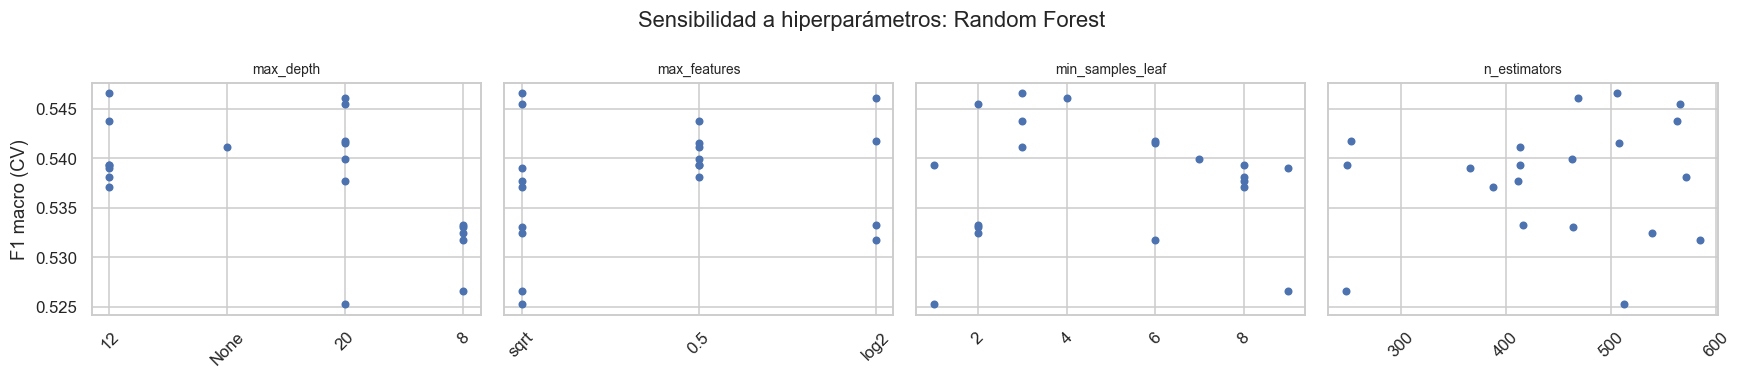

In [29]:
# ¿Qué hiperparámetros importan? (rendimiento medio por valor probado)
nombre = A_AFINAR[0]
cvr = pd.DataFrame(mejores[nombre].cv_results_)
cols_p = [c for c in cvr.columns if c.startswith("param_")]
fig, axs = plt.subplots(1, len(cols_p), figsize=(4 * len(cols_p), 3.5), sharey=True)
for ax, c in zip(np.atleast_1d(axs), cols_p):
    # Valores numéricos se dibujan como números; los mixtos (p. ej. None y enteros) o de texto, como categorías
    num = pd.to_numeric(pd.Series(cvr[c].tolist()), errors="coerce")
    ax.scatter(num if num.notna().all() else [str(v) for v in cvr[c]], cvr["mean_test_score"], s=18)
    ax.set_title(c.replace("param_clf__", ""), fontsize=9); ax.tick_params(axis="x", rotation=45)
np.atleast_1d(axs)[0].set_ylabel("F1 macro (CV)")
plt.suptitle(f"Sensibilidad a hiperparámetros: {nombre}"); plt.tight_layout(); plt.show()

**Interpretación.** La búsqueda aleatoria apenas mueve el resultado: Random Forest pasa de 0.527 a 0.547 y HistGradientBoosting queda en 0.552 (frente a 0.551 sin afinar). El gráfico muestra un rendimiento casi plano: la única tendencia clara es que una profundidad de 8 es peor que 12 o 20 en Random Forest. Los demás hiperparámetros cambian el F1 en menos de dos centésimas. Se elige HistGradientBoosting por mejor F1 en validación cruzada y menor tiempo. El SVM, que fue ligeramente mejor sin afinar, no se incluyó en la búsqueda por su costo; es una opción a probar.

In [30]:
candidatos = {n: b.best_score_ for n, b in mejores.items()}
nombre_final = max(candidatos, key=candidatos.get)
modelo_final = mejores[nombre_final].best_estimator_
print("Modelo elegido:", nombre_final, "| F1 macro CV:", round(candidatos[nombre_final], 3))
print(mejores[nombre_final].best_params_)

Modelo elegido: HistGradientBoosting | F1 macro CV: 0.552
{'clf__l2_regularization': np.float64(0.24400607090817547), 'clf__learning_rate': np.float64(0.06689135590392836), 'clf__max_iter': 364, 'clf__max_leaf_nodes': 18, 'clf__min_samples_leaf': 33}


---
# 12. Evaluación en test

El conjunto de test (pacientes no vistos) se usa **una sola vez**, con el modelo ya elegido. No se vuelve a afinar nada después de ver estos números.

## Métricas y por qué

| Métrica | Por qué |
|---|---|
| **Recall por clase** | En clínica importa no perder una arritmia peligrosa (falso negativo) |
| **Precisión por clase** | Muchas falsas alarmas causan fatiga de alarmas y que el personal ignore el sistema |
| **F1 macro** | Resume ambas con el mismo peso por clase |
| **PR-AUC** (average precision) por clase | Más informativa que ROC cuando hay desbalance |
| **Exactitud balanceada** y **MCC** | Resúmenes robustos al desbalance |
| Matriz de confusión | Muestra *con qué* se confunde cada clase |

La exactitud global se reporta solo como referencia, porque Normal domina.

In [31]:
y_pred = modelo_final.predict(X_te)
clases = list(modelo_final.classes_)
print(classification_report(y_te, y_pred, digits=3, zero_division=0))
print("F1 macro:", round(f1_score(y_te, y_pred, average="macro"), 3),
      "| Exactitud balanceada:", round(balanced_accuracy_score(y_te, y_pred), 3),
      "| MCC:", round(matthews_corrcoef(y_te, y_pred), 3))

                         precision    recall  f1-score   support

                   AFib      0.844     0.926     0.883       996
             Bloqueo AV      0.375     0.056     0.097        54
Disfuncion nodo sinusal      0.466     0.461     0.464       436
      Ectopia auricular      0.695     0.706     0.701       262
    Ectopia ventricular      0.856     0.813     0.834       299
                 Normal      0.841     0.838     0.839       997
                  Ruido      1.000     1.000     1.000        83
                   SVTA      0.752     0.907     0.822        97
                     TV      0.727     0.681     0.703        47
                WAP/MAT      0.065     0.047     0.054       171

               accuracy                          0.755      3442
              macro avg      0.662     0.643     0.640      3442
           weighted avg      0.738     0.755     0.744      3442

F1 macro: 0.64 | Exactitud balanceada: 0.643 | MCC: 0.692


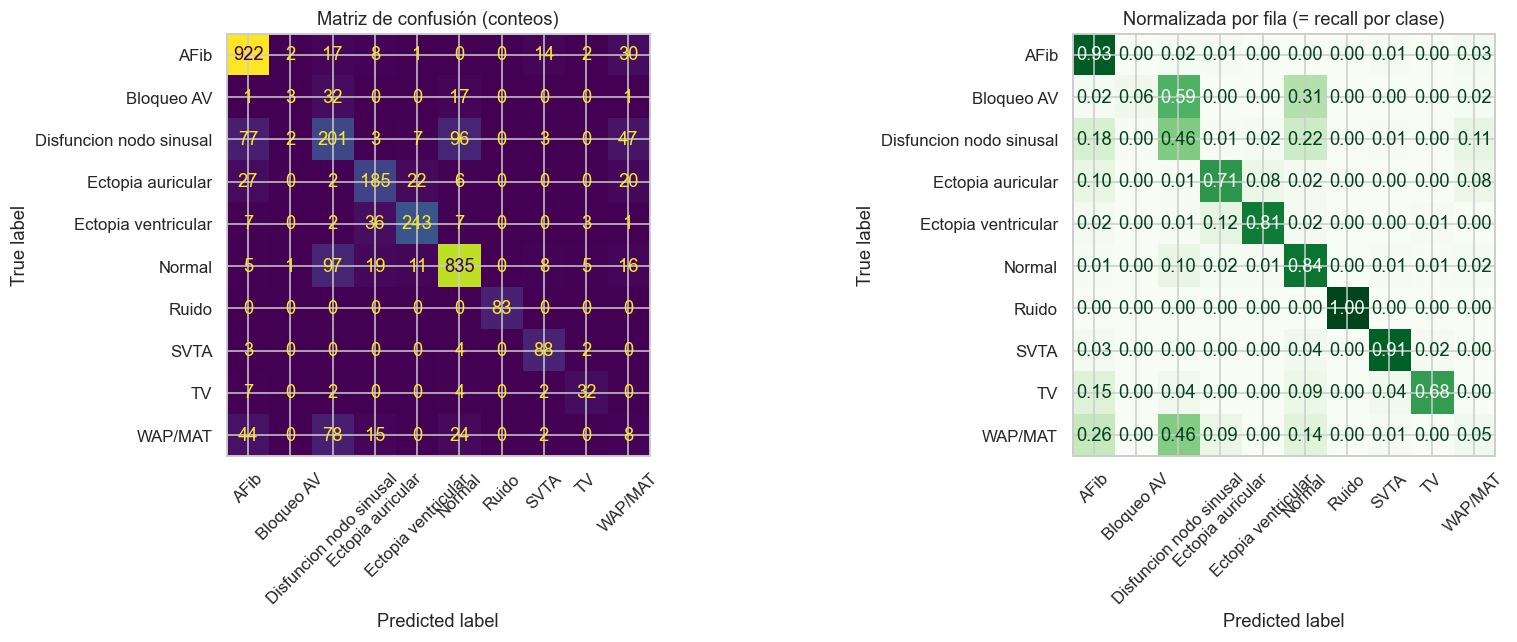

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
ConfusionMatrixDisplay.from_predictions(y_te, y_pred, labels=clases, xticks_rotation=45, ax=ax[0], colorbar=False)
ax[0].set_title("Matriz de confusión (conteos)")
ConfusionMatrixDisplay.from_predictions(y_te, y_pred, labels=clases, xticks_rotation=45, normalize="true",
                                        values_format=".2f", ax=ax[1], colorbar=False, cmap="Greens")
ax[1].set_title("Normalizada por fila (= recall por clase)")
plt.tight_layout(); plt.savefig(FIGURAS / "eval_confusion.png"); plt.show()

PR-AUC por clase: {'AFib': 0.958, 'Bloqueo AV': 0.095, 'Disfuncion nodo sinusal': 0.406, 'Ectopia auricular': 0.754, 'Ectopia ventricular': 0.921, 'Normal': 0.913, 'Ruido': 1.0, 'SVTA': 0.799, 'TV': 0.754, 'WAP/MAT': 0.069} | macro: 0.667


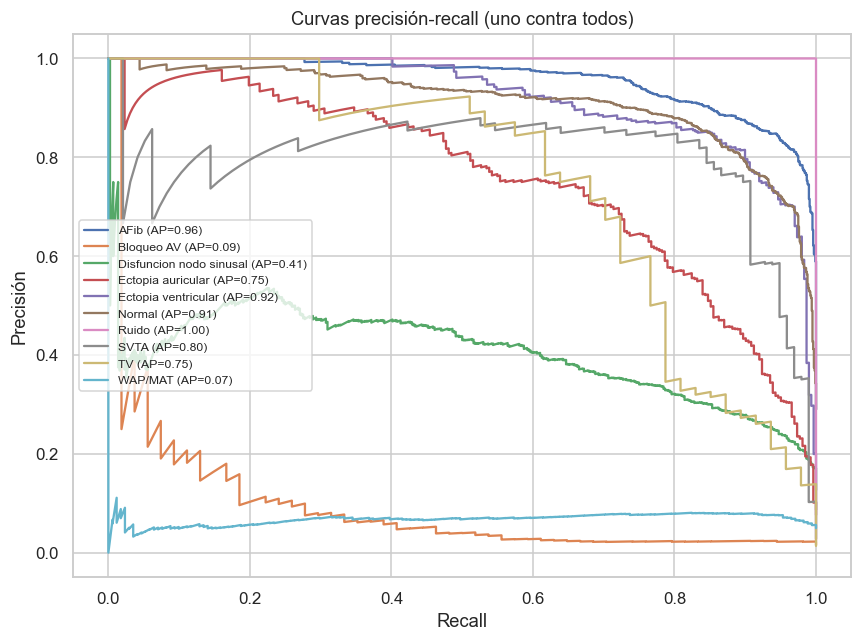

In [33]:
proba = modelo_final.predict_proba(X_te)
Y = label_binarize(y_te, classes=clases)
aps = {c: average_precision_score(Y[:, i], proba[:, i]) for i, c in enumerate(clases) if Y[:, i].sum() > 0}
print("PR-AUC por clase:", {k: round(v, 3) for k, v in aps.items()}, "| macro:", round(np.mean(list(aps.values())), 3))

plt.figure(figsize=(8, 6))
for i, c in enumerate(clases):
    if Y[:, i].sum() == 0: continue
    p, r, _ = precision_recall_curve(Y[:, i], proba[:, i])
    plt.plot(r, p, label=f"{c} (AP={aps[c]:.2f})")
plt.xlabel("Recall"); plt.ylabel("Precisión"); plt.title("Curvas precisión-recall (uno contra todos)")
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig(FIGURAS / "eval_pr.png"); plt.show()

**Interpretación.** En test (94 pacientes nuevos) el modelo logra **F1 macro 0.64**, exactitud balanceada 0.64 y MCC 0.69.

- **Clases que funcionan** (F1 ≥ 0.80): Ruido (1.00), AFib (0.88, recall 0.93), Normal (0.84), Ectopia ventricular (0.83) y SVTA (0.82, recall 0.91). La regla de etiquetado por salvas breves funcionó para SVTA.
- **Intermedias**: TV (0.70; el 15 % se confunde con AFib) y Ectopia auricular (0.70; se confunde con Ectopia ventricular y AFib).
- **Difíciles**: Disfunción del nodo sinusal (0.46), confundida con Normal (22 %) y AFib (18 %); **Bloqueo AV (0.10)**, que se predice como Disfunción del nodo (59 %) o Normal (31 %); y **WAP/MAT (0.05)**, que se predice como Disfunción del nodo (46 %) o AFib (26 %). Clínicamente es esperable: estas tres clases se distinguen por la **onda P** y su relación con el QRS, información que nuestras características no miden. Además, Bloqueo AV y WAP/MAT vienen de 10 y 23 pacientes.
- **Costo de los errores**: el 15 % de las TV va a AFib y el 9 % a Normal. Confundir TV con AFib aún genera alerta, pero TV como Normal es el error grave; se puede reducir bajando el umbral de decisión de TV (ver curva PR, AP = 0.75).
- **PR-AUC** coincide con el F1: alta en Ruido (1.00), AFib (0.96), Ectopia ventricular (0.92) y Normal (0.91); muy baja en WAP/MAT (0.07) y Bloqueo AV (0.10).

---
# 13. Explicabilidad

Se usan dos técnicas complementarias:

- **Importancia por permutación** (global): cuánto cae el F1 macro si se mezcla una variable. Funciona con cualquier modelo.
- **SHAP** (valores de Shapley): contribución de cada variable a cada predicción. Muestra no solo *cuánto* importa una variable sino *en qué dirección* empuja la predicción de cada clase.

La explicabilidad sirve en la presentación para mostrar que el modelo aprende **señales fisiológicamente plausibles** (irregularidad del RR para AFib, ruido de alta frecuencia para Ruido) y no artefactos.

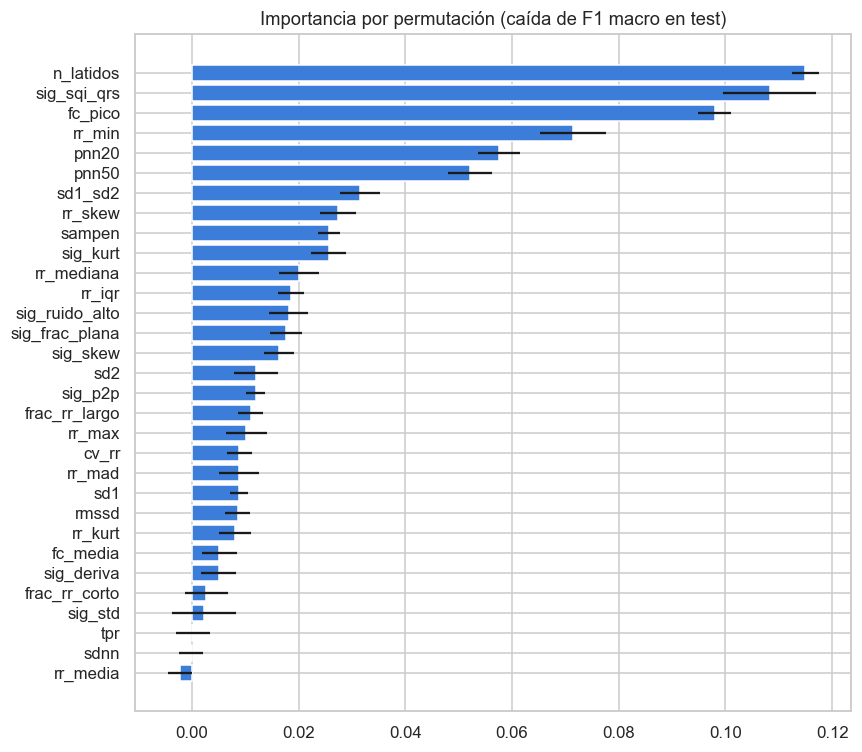

In [34]:
perm = permutation_importance(modelo_final, X_te, y_te, scoring="f1_macro", n_repeats=10, random_state=SEMILLA, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=COLS).sort_values()
imp_std = pd.Series(perm.importances_std, index=COLS)[imp.index]
plt.figure(figsize=(8, 7))
plt.barh(imp.index, imp.values, xerr=imp_std.values, color="#3b7dd8")
plt.title("Importancia por permutación (caída de F1 macro en test)"); plt.tight_layout()
plt.savefig(FIGURAS / "explic_permutacion.png"); plt.show()

SHAP calculado para 10 clases


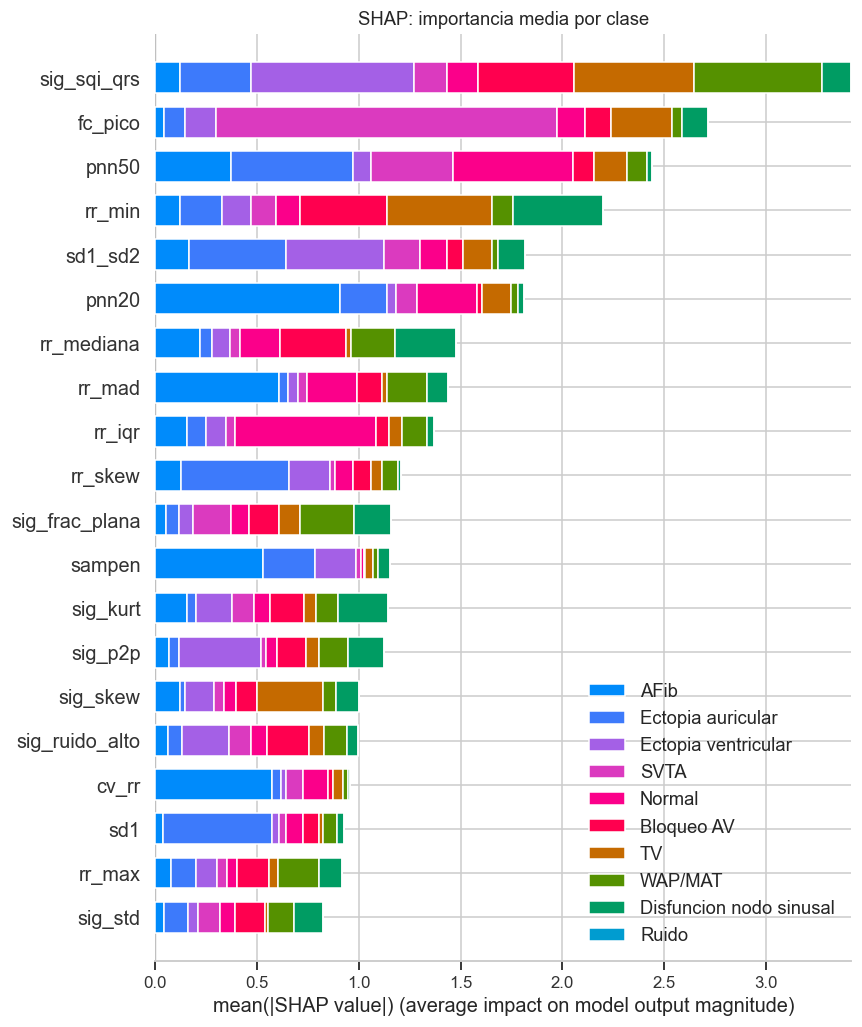

In [35]:
import shap

clf_final = modelo_final.named_steps["clf"]
pre = modelo_final[:-1]                                  # imputer/scaler si existen
rng = np.random.default_rng(SEMILLA)
idx = rng.choice(len(X_te), size=min(500, len(X_te)), replace=False)
X_muestra = pd.DataFrame(pre.transform(X_te.iloc[idx]) if len(pre.steps) else X_te.iloc[idx].values, columns=COLS)

if isinstance(clf_final, (RandomForestClassifier, HistGradientBoostingClassifier)):
    explicador = shap.TreeExplainer(clf_final)
else:  # modelos no arbóreos: explicador agnóstico (lento, usar pocas muestras)
    fondo = shap.sample(X_muestra, 50, random_state=SEMILLA)
    explicador = shap.KernelExplainer(clf_final.predict_proba, fondo)
sv = explicador.shap_values(X_muestra if not isinstance(explicador, shap.KernelExplainer) else X_muestra.iloc[:100])

# Unificar el formato según la versión de SHAP: lista por clase, o arreglo (muestras, variables, clases)
sv_cls = [sv[i] for i in range(len(sv))] if isinstance(sv, list) else [sv[:, :, i] for i in range(sv.shape[2])]
print("SHAP calculado para", len(sv_cls), "clases")

shap.summary_plot(sv_cls, X_muestra.iloc[:len(sv_cls[0])], class_names=clases, plot_type="bar", show=False)
plt.title("SHAP: importancia media por clase"); plt.tight_layout(); plt.savefig(FIGURAS / "explic_shap_global.png"); plt.show()

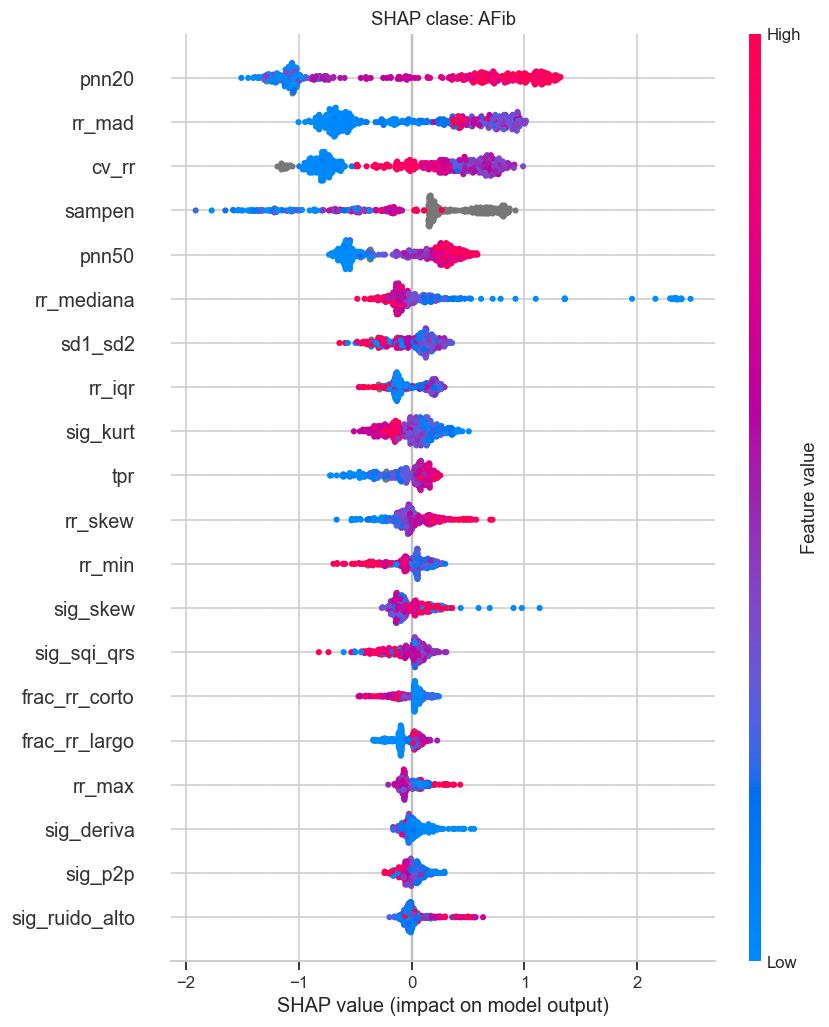

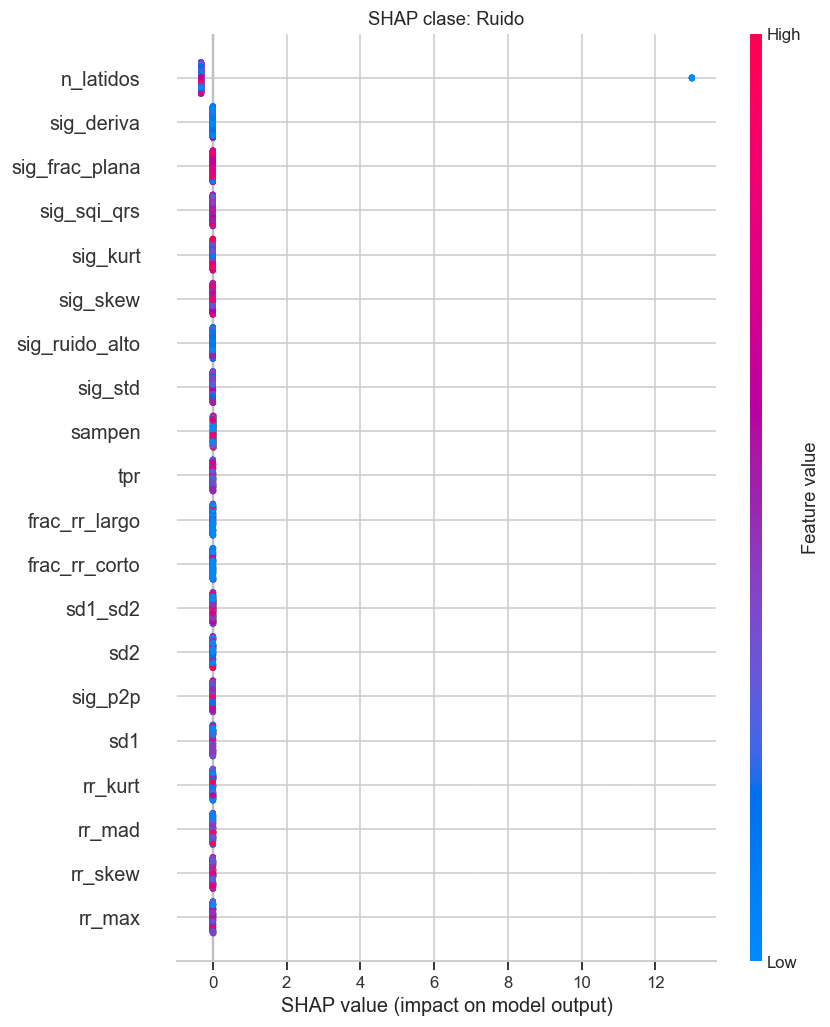

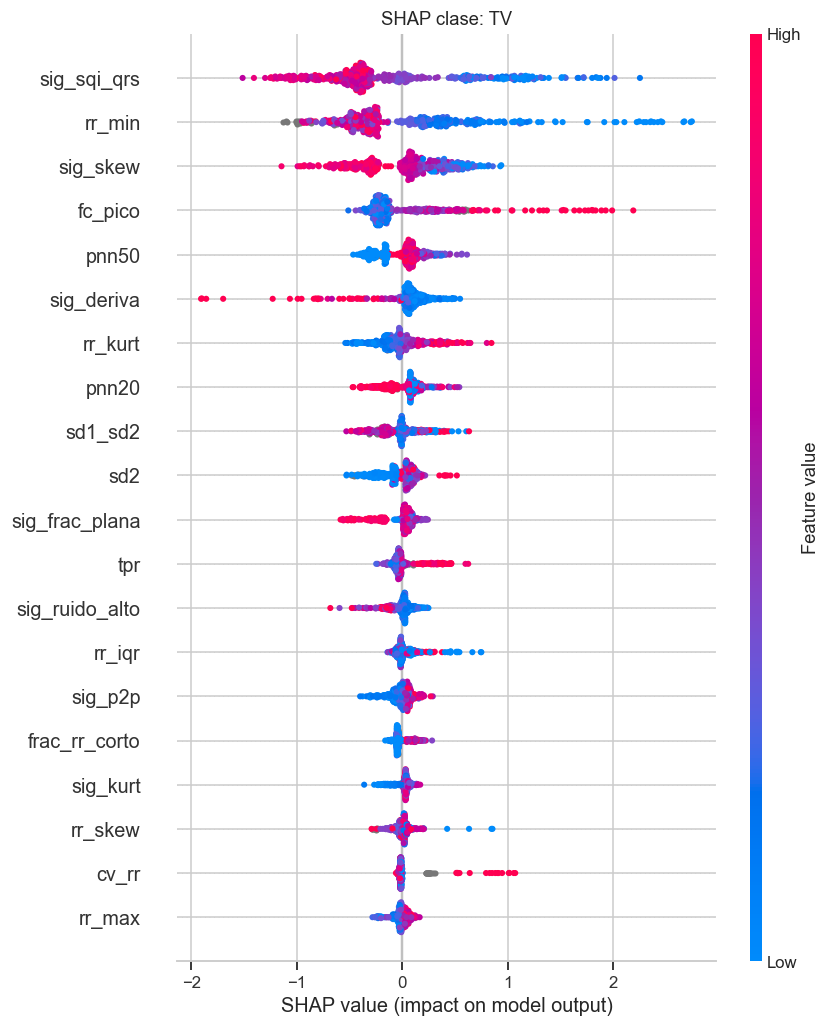

In [36]:
# SHAP por clase de interés: dirección del efecto de cada variable
for c in [k for k in ["AFib", "Ruido", "TV"] if k in clases]:
    i = clases.index(c)
    shap.summary_plot(sv_cls[i], X_muestra.iloc[:len(sv_cls[i])], show=False)
    plt.title(f"SHAP clase: {c}"); plt.tight_layout(); plt.show()

**Interpretación.**

- **Plausibilidad fisiológica**: para **AFib** dominan `pnn20`, `rr_mad`, `cv_rr` y `pnn50` con valores altos: el modelo reconoce la irregularidad, como se espera. Para **TV** pesan `sig_sqi_qrs` bajo (QRS ancho con menos energía en 5-15 Hz), `rr_min` bajo y `fc_pico` alto (ráfaga rápida): también coherente con la clínica. En importancia global destacan `sig_sqi_qrs`, `fc_pico`, `rr_min`, `pnn20` y `pnn50`.
- **Alerta: posible atajo en Ruido.** La variable más importante por permutación es `n_latidos`, y en SHAP la clase Ruido depende casi solo de ella. La razón es que en entrenamiento los latidos salen de las **anotaciones**, y en los tramos de ruido no hay latidos anotados (`n_latidos` ≈ 0). En producción los picos vendrán del detector, que sí encontrará picos falsos en el ruido. El F1 de 1.00 en Ruido probablemente **sobreestima** lo que pasará en la app. La solución es entrenar con `FUENTE_PICOS = "detectados"` y comparar.
- `sampen` aparece con valores grises (faltantes) en SHAP: confirma que en ventanas de 10 s casi no se puede calcular.

---
# 14. Evidencia de generalización y ausencia de fuga de datos

Cuatro pruebas independientes. Juntas sostienen que el rendimiento es real y no producto de sobreajuste o de fuga.

| Prueba | Pregunta que responde |
|---|---|
| 14.1 Brecha train, CV y test | ¿Hay sobreajuste? |
| 14.2 Validación aleatoria vs agrupada | ¿Cuánta fuga habría sin separar por paciente? |
| 14.3 Prueba de etiquetas permutadas | ¿El modelo aprende algo real o explota estructura espuria? |
| 14.4 Curva de aprendizaje e incertidumbre | ¿Más datos ayudan? ¿Qué tan fiable es la métrica de test? |

In [37]:
# 14.1 Brecha entre rendimientos
f1_train = f1_score(y_tr, modelo_final.predict(X_tr), average="macro")
f1_cv = mejores[nombre_final].best_score_
f1_test = f1_score(y_te, y_pred, average="macro")
pd.DataFrame({"F1 macro": [f1_train, f1_cv, f1_test]}, index=["Train (reajustado)", "Validación cruzada por paciente", "Test (pacientes nuevos)"]).round(3)

,F1 macro
Train (reajustado),0.954
Validación cruzada por paciente,0.552
Test (pacientes nuevos),0.640


In [38]:
# 14.2 Demostración de la fuga: validación aleatoria (INCORRECTA) vs agrupada por paciente (CORRECTA)
from sklearn.model_selection import StratifiedKFold
f_alea = cross_validate(clone(modelo_final), X_tr, y_tr, cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA), scoring="f1_macro")["test_score"]
f_agr = cross_validate(clone(modelo_final), X_tr, y_tr, groups=g_tr, cv=cv, scoring="f1_macro")["test_score"]
print(f"CV aleatoria (con fuga):      F1 macro = {f_alea.mean():.3f} ± {f_alea.std():.3f}")
print(f"CV agrupada por paciente:     F1 macro = {f_agr.mean():.3f} ± {f_agr.std():.3f}")
print(f"Inflación por fuga:           {f_alea.mean() - f_agr.mean():+.3f}")

CV aleatoria (con fuga):      F1 macro = 0.839 ± 0.010
CV agrupada por paciente:     F1 macro = 0.552 ± 0.044
Inflación por fuga:           +0.288


In [39]:
# 14.3 Etiquetas permutadas (se barajan entre todas las ventanas de train): si el F1 sigue alto con etiquetas al azar, hay fuga o estructura espuria
rng = np.random.default_rng(SEMILLA)
y_perm = y_tr.copy()
y_perm = pd.Series(rng.permutation(y_tr.values), index=y_tr.index)
f_perm = cross_validate(clone(modelo_final), X_tr, y_perm, groups=g_tr, cv=cv, scoring="f1_macro")["test_score"]
print(f"F1 macro con etiquetas permutadas: {f_perm.mean():.3f} ± {f_perm.std():.3f}  (azar esperado ≈ {1/y_tr.nunique():.2f} o menos)")
print(f"F1 macro con etiquetas reales:     {f_agr.mean():.3f}")

F1 macro con etiquetas permutadas: 0.077 ± 0.004  (azar esperado ≈ 0.10 o menos)
F1 macro con etiquetas reales:     0.552


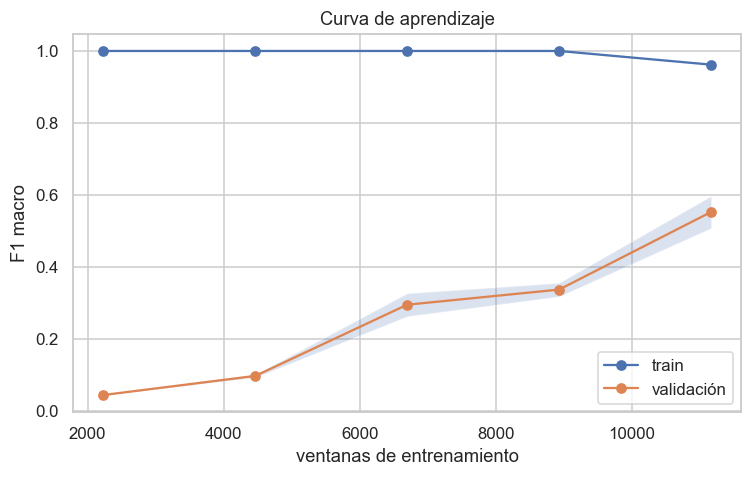

In [40]:
# 14.4a Curva de aprendizaje (por paciente)
tamanos, tr_sc, va_sc = learning_curve(clone(modelo_final), X_tr, y_tr, groups=g_tr, cv=cv, scoring="f1_macro",
                                        train_sizes=np.linspace(0.2, 1.0, 5), n_jobs=-1,
                                        shuffle=True, random_state=SEMILLA)   # shuffle: datos está ordenado por clase
plt.figure(figsize=(7, 4.5))
plt.plot(tamanos, tr_sc.mean(1), "o-", label="train"); plt.plot(tamanos, va_sc.mean(1), "o-", label="validación")
plt.fill_between(tamanos, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=.2)
plt.xlabel("ventanas de entrenamiento"); plt.ylabel("F1 macro"); plt.title("Curva de aprendizaje"); plt.legend(); plt.tight_layout()
plt.savefig(FIGURAS / "gen_curva_aprendizaje.png"); plt.show()

In [41]:
# 14.4b Intervalo de confianza del F1 macro de test por bootstrap a nivel de PACIENTE
rng = np.random.default_rng(SEMILLA)
pac = g_te.unique(); vals = []
for _ in range(300):
    muestra = rng.choice(pac, size=len(pac), replace=True)
    ii = np.concatenate([np.where(g_te.values == p)[0] for p in muestra])
    vals.append(f1_score(y_te.iloc[ii], y_pred[ii], average="macro"))
lo, hi = np.percentile(vals, [2.5, 97.5])
print(f"F1 macro test = {f1_test:.3f}  IC95% por bootstrap de pacientes: [{lo:.3f}, {hi:.3f}]")

F1 macro test = 0.640  IC95% por bootstrap de pacientes: [0.550, 0.672]


**Interpretación.**

- **14.1**: el F1 macro en train es 0.95, frente a 0.55 en validación cruzada y 0.64 en test. Los árboles memorizan el entrenamiento, pero lo que importa es que la estimación en pacientes nuevos sea honesta. El test salió mejor que la validación cruzada: este grupo de 94 pacientes fue algo más fácil, y el intervalo por bootstrap ([0.55, 0.67]) muestra que la cifra realista está entre ambos valores. **Para la presentación conviene reportar 0.55 a 0.64, no solo 0.64.**
- **14.2**: con validación aleatoria el F1 sería **0.84**; separando por paciente baja a **0.55**. La fuga habría inflado el resultado en **+0.29**: es la prueba más clara de por qué se particiona por paciente.
- **14.3**: con etiquetas barajadas el F1 cae a 0.08, por debajo del azar (≈ 0.10). No hay fuga ni estructura espuria: el modelo aprende la relación real entre señal y ritmo.
- **14.4a**: **la curva de aprendizaje de esta ejecución no es válida.** `learning_curve` toma subconjuntos en el orden de las filas, y `datos` quedó ordenado por clase al aplicar el tope, así que los subconjuntos pequeños tenían solo algunas clases (de ahí el F1 de 0.04 a 0.34). Ya se corrigió el código con `shuffle=True`; hay que **volver a ejecutar esa celda** e interpretar: si la curva de validación sigue subiendo al final, más datos (más pacientes de las clases raras) ayudarían.
- **14.4b**: IC95 % del F1 macro en test por bootstrap de pacientes: [0.55, 0.67].
- **Pendiente honesto**: no se ha probado en otro hospital ni dispositivo. Ver sección 17.

---
# 15. Guardado del modelo y despliegue

## 15.1 Reajuste final y guardado

Una vez justificado el modelo y la metodología con la partición por paciente, el modelo que se despliega se **reajusta con todos los datos** (train + test) para aprovechar los pacientes disponibles. Se guarda junto con la lista exacta de características, las clases y los parámetros de ventaneo, para que la app use exactamente el mismo preprocesamiento (`src/ecg_utils.py`).

In [42]:
modelo_prod = clone(modelo_final).fit(X, y)
meta_modelo = {
    "version": time.strftime("%Y.%m.%d"), "modelo": nombre_final, "clases": list(modelo_prod.classes_),
    "columnas": COLS, "ventana_s": VENTANA_S, "fs": FS, "usa_senal": USAR_SENAL,
    "f1_macro_cv": float(f1_cv), "f1_macro_test": float(f1_test), "n_ventanas": int(len(X)), "n_pacientes": int(grupos.nunique()),
}
joblib.dump({"modelo": modelo_prod, "meta": meta_modelo}, MODELOS / "modelo_arritmias.joblib", compress=3)

# Distribución de referencia para el monitoreo de drift (sección 16)
datos[COLS].describe().T.to_csv(MODELOS / "referencia_features.csv")
datos[COLS].sample(min(5000, len(datos)), random_state=SEMILLA).to_csv(MODELOS / "referencia_muestra.csv", index=False)
(MODELOS / "meta_modelo.json").write_text(json.dumps(meta_modelo, indent=2, ensure_ascii=False))
print(json.dumps(meta_modelo, indent=2, ensure_ascii=False))

{
  "version": "2026.10.25",
  "modelo": "HistGradientBoosting",
  "clases": [
    "AFib",
    "Bloqueo AV",
    "Disfuncion nodo sinusal",
    "Ectopia auricular",
    "Ectopia ventricular",
    "Normal",
    "Ruido",
    "SVTA",
    "TV",
    "WAP/MAT"
  ],
  "columnas": [
    "n_latidos",
    "fc_media",
    "fc_pico",
    "rr_media",
    "rr_mediana",
    "sdnn",
    "rmssd",
    "pnn50",
    "pnn20",
    "cv_rr",
    "rr_min",
    "rr_max",
    "rr_iqr",
    "rr_mad",
    "rr_skew",
    "rr_kurt",
    "sd1",
    "sd2",
    "sd1_sd2",
    "frac_rr_corto",
    "frac_rr_largo",
    "tpr",
    "sampen",
    "sig_std",
    "sig_p2p",
    "sig_skew",
    "sig_kurt",
    "sig_sqi_qrs",
    "sig_ruido_alto",
    "sig_deriva",
    "sig_frac_plana"
  ],
  "ventana_s": 10,
  "fs": 500,
  "usa_senal": true,
  "f1_macro_cv": 0.5516906666879151,
  "f1_macro_test": 0.6396882163106891,
  "n_ventanas": 17372,
  "n_pacientes": 482
}


## 15.2 Interfaz para personas no técnicas

Se genera una aplicación **Streamlit** (`app/app.py`). Está pensada para personal clínico:

- Sube un ECG (CSV de una columna con la señal) o usa un ejemplo incluido.
- Indica la frecuencia de muestreo (500 Hz por defecto).
- Muestra la **señal con el ritmo predicho por tramos de 10 s** en colores, una tabla en lenguaje claro y una advertencia de que es una herramienta de apoyo.
- Marca las ventanas con **baja confianza** para revisión humana.

Para ejecutarla en local: `streamlit run app/app.py`. Para publicarla gratis: Streamlit Community Cloud o Hugging Face Spaces, apuntando al repositorio.

In [43]:
APP = r"""
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
import streamlit as st

RAIZ = Path(__file__).resolve().parent.parent
sys.path.insert(0, str(RAIZ / "src"))
import ecg_utils as eu

st.set_page_config(page_title="Apoyo a la detección de arritmias", layout="wide")
st.title("Apoyo a la detección de arritmias en cirugía")
st.caption("Herramienta de apoyo. No reemplaza el criterio clínico ni diagnostica.")

@st.cache_resource
def cargar():
    d = joblib.load(RAIZ / "models" / "modelo_arritmias.joblib")
    return d["modelo"], d["meta"]
modelo, meta = cargar()

NOMBRES = {"Normal": "Ritmo normal", "AFib": "Fibrilación auricular", "SVTA": "Taquicardia supraventricular",
           "TV": "Taquicardia ventricular", "Ectopia ventricular": "Latidos ventriculares prematuros",
           "Ectopia auricular": "Latidos auriculares prematuros", "Disfuncion nodo sinusal": "Disfunción del nodo sinusal",
           "WAP/MAT": "Ritmo auricular multifocal", "Ruido": "Señal con ruido (no interpretable)"}
ALERTA = {"AFib", "SVTA", "TV"}

col1, col2 = st.columns([2, 1])
with col2:
    fs = st.number_input("Frecuencia de muestreo (Hz)", 100, 1000, int(meta["fs"]))
    umbral = st.slider("Confianza mínima para no marcar revisión", 0.3, 0.95, 0.6)
    archivo = st.file_uploader("ECG en CSV (una columna con la señal)", type=["csv", "txt"])
if archivo is None:
    st.info("Sube un archivo para empezar.")
    st.stop()

x = pd.read_csv(archivo, header=None).iloc[:, -1].astype(float).values
if fs != meta["fs"]:
    from scipy.signal import resample
    x = resample(x, int(len(x) * meta["fs"] / fs)); fs = meta["fs"]
vent = int(meta["ventana_s"] * fs)
filas = []
for i in range(0, len(x) - vent + 1, vent):
    seg = x[i:i + vent]
    picos = eu.detectar_picos_r(seg, fs)
    f = eu.features_ventana(picos, seg if meta["usa_senal"] else None, fs)
    p = modelo.predict_proba(pd.DataFrame([f])[meta["columnas"]])[0]
    k = int(np.argmax(p))
    filas.append({"inicio_s": i / fs, "clase": modelo.classes_[k], "confianza": p[k], "fc": f["fc_media"]})
res = pd.DataFrame(filas)
if res.empty:
    st.error("La señal es más corta que una ventana."); st.stop()
res["Ritmo"] = res.clase.map(NOMBRES).fillna(res.clase)
res["Revisar"] = (res.confianza < umbral) | res.clase.isin(ALERTA)

with col1:
    t = np.arange(len(x)) / fs
    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.plot(t, eu.filtrar_ecg(x, fs), lw=0.5, color="k")
    for _, r in res.iterrows():
        c = "#d9534f" if r.clase in ALERTA else ("#999999" if r.clase == "Ruido" else "#5cb85c")
        ax.axvspan(r.inicio_s, r.inicio_s + meta["ventana_s"], color=c, alpha=0.18)
    ax.set_xlabel("segundos"); ax.set_yticks([])
    st.pyplot(fig)
st.subheader(f"Resumen por tramo de {meta['ventana_s']} segundos")
st.dataframe(res[["inicio_s", "Ritmo", "confianza", "fc", "Revisar"]].round(2), use_container_width=True)
n = int(res.Revisar.sum())
(st.warning if n else st.success)(f"{n} de {len(res)} tramos conviene revisarlos." if n else "Ningún tramo requiere revisión según el modelo.")
st.caption(f"Modelo {meta['modelo']} v{meta['version']}. Entrenado con VitalDB Arrhythmia (un hospital, Corea).")
"""
(RAIZ / "app").mkdir(exist_ok=True)
(RAIZ / "app" / "app.py").write_text(APP.lstrip(), encoding="utf-8")
(RAIZ / "requirements.txt").write_text("numpy\npandas\nscipy\nscikit-learn\nmatplotlib\nseaborn\njoblib\nshap\nvitaldb\nstreamlit\ntqdm\n")
print("Escrito app/app.py y requirements.txt")

Escrito app/app.py y requirements.txt


In [44]:
# Ejemplo de ECG para probar la app: un caso de la caché, 5 minutos
if casos_con_ecg:
    cid = casos_con_ecg[0]
    ecg, off = eu.cargar_ecg_cache(cid, ECG_DIR)
    ejemplo = ecg[: 5 * 60 * FS]
    (RAIZ / "app" / "ejemplos").mkdir(exist_ok=True)
    np.savetxt(RAIZ / "app" / "ejemplos" / f"ecg_caso_{cid}.csv", ejemplo, fmt="%.4f")
    print("Ejemplo guardado para la app:", f"ecg_caso_{cid}.csv")

Ejemplo guardado para la app: ecg_caso_1001.csv


**Interpretación.** El modelo final (HistGradientBoosting, 10 clases, 31 características, ventanas de 10 s) se reajustó con las 17,372 ventanas de los 482 pacientes y se guardó con sus metadatos y la distribución de referencia para el monitoreo. La app y un ECG de ejemplo (caso 1001, 5 minutos) quedaron en `app/`. Para el video conviene preparar tres ejemplos (normal, AFib y ruido) y mostrar que el sistema marca para revisión las clases de alerta y las predicciones con baja confianza. Recordar la advertencia de la sección 13: la clase Ruido en la app puede comportarse peor que en el test, porque allí los picos vienen del detector.

In [45]:
# Implementación del monitoreo: PSI y KS contra la distribución de referencia
def psi(ref, nuevo, bins=10):
    ref, nuevo = pd.Series(ref).dropna(), pd.Series(nuevo).dropna()
    cortes = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(cortes) < 3:
        return 0.0
    cortes[0], cortes[-1] = -np.inf, np.inf
    a = np.histogram(ref, cortes)[0] / len(ref)
    b = np.histogram(nuevo, cortes)[0] / len(nuevo)
    a, b = np.clip(a, 1e-4, None), np.clip(b, 1e-4, None)
    return float(np.sum((b - a) * np.log(b / a)))

def reporte_drift(ref_df, nuevo_df, cols):
    filas = []
    for c in cols:
        ks = stats.ks_2samp(ref_df[c].dropna(), nuevo_df[c].dropna())
        p = psi(ref_df[c], nuevo_df[c])
        filas.append((c, p, ks.statistic, ks.pvalue, "ALTO" if p > 0.2 else ("moderado" if p > 0.1 else "estable")))
    return pd.DataFrame(filas, columns=["variable", "PSI", "KS", "p_KS", "estado"]).sort_values("PSI", ascending=False)

# Simulación: "nuevo hospital" = pacientes de otra mitad de case_id + ruido de señal más alto
ref = datos[datos.case_id < datos.case_id.median()]
nuevo = datos[datos.case_id >= datos.case_id.median()].copy()
reporte_drift(ref, nuevo, COLS).head(10)

,variable,PSI,KS,p_KS,estado
24,sig_p2p,0.116333,0.137908,1.896724e-72,moderado
23,sig_std,0.114298,0.146664,6.469066e-82,moderado
30,sig_frac_plana,0.108478,0.107228,6.320368e-44,moderado
10,rr_min,0.085433,0.115799,5.948580e-50,estable
4,rr_mediana,0.057001,0.093000,2.370196e-32,estable
2,fc_pico,0.047785,0.089267,7.723260e-30,estable
28,sig_ruido_alto,0.041261,0.068175,5.326014e-18,estable
5,sdnn,0.041190,0.068826,6.591053e-18,estable
3,rr_media,0.039220,0.082160,2.438361e-25,estable
1,fc_media,0.039217,0.082160,2.438361e-25,estable


In [46]:
# Simulación de un cambio de equipo: más ruido de alta frecuencia y señal más baja
nuevo_ruidoso = nuevo.copy()
for c in [k for k in ["sig_ruido_alto"] if k in nuevo_ruidoso]:
    nuevo_ruidoso[c] *= 3
for c in [k for k in ["sig_std", "sig_p2p"] if k in nuevo_ruidoso]:
    nuevo_ruidoso[c] *= 0.6
rep = reporte_drift(ref, nuevo_ruidoso, COLS)
display(rep.head(6))
print("Variables en estado ALTO:", (rep.estado == "ALTO").sum(), "-> criterio de reentrenamiento si persiste y es en variables importantes")

,variable,PSI,KS,p_KS,estado
28,sig_ruido_alto,2.013410,0.573097,0.000000e+00,ALTO
23,sig_std,1.688544,0.526624,0.000000e+00,ALTO
24,sig_p2p,1.505188,0.494807,0.000000e+00,ALTO
30,sig_frac_plana,0.108478,0.107228,6.320368e-44,moderado
10,rr_min,0.085433,0.115799,5.948580e-50,estable
4,rr_mediana,0.057001,0.093000,2.370196e-32,estable


Variables en estado ALTO: 3 -> criterio de reentrenamiento si persiste y es en variables importantes


**Interpretación.** Al comparar dos mitades de pacientes del **mismo hospital**, ninguna variable llega a estado ALTO: las de RR son estables (PSI < 0.09) y solo tres de señal (`sig_p2p`, `sig_std`, `sig_frac_plana`) quedan en moderado (PSI ≈ 0.11 a 0.12). Esto sugiere un cambio leve de amplitud entre periodos o equipos dentro del propio hospital, que no alcanza para alarmar. En la simulación de **un equipo distinto**, las tres variables de señal alteradas pasan a ALTO (PSI de 1.5 a 2.0) y el resto no cambia. El mecanismo detecta el cambio real sin falsas alarmas. Como `sig_sqi_qrs` es una de las variables más importantes, un cambio de equipo afectaría directamente el desempeño: es un buen disparador de reentrenamiento.

---
# 17. Conclusiones, limitaciones y trabajo futuro

## 17.1 Conclusiones

- Se construyó un clasificador de ritmo cardíaco intraoperatorio con ML tradicional sobre ventanas de 10 s de ECG de una derivación, con 31 características de intervalos RR y de calidad de señal. El mejor modelo, **HistGradientBoosting**, logra un **F1 macro de 0.55 en validación cruzada por paciente y de 0.64 en test** con 94 pacientes nuevos (IC95 % [0.55, 0.67]), frente a 0.045 de la línea base trivial.
- **Bien resueltas**: Ruido, AFib, Normal, Ectopia ventricular y SVTA (F1 0.82 a 1.00). **Intermedias**: TV y Ectopia auricular (0.70). **Difíciles**: Disfunción del nodo sinusal (0.46), Bloqueo AV (0.10) y WAP/MAT (0.05), que se distinguen por la onda P y tienen pocos pacientes.
- Las variables más influyentes son fisiológicamente coherentes: irregularidad del RR para AFib (`pnn20`, `cv_rr`) y QRS ancho y frecuencia máxima para TV (`sig_sqi_qrs`, `fc_pico`, `rr_min`).
- Cuatro algoritmos muy distintos llegan al mismo techo (0.53 a 0.56), y afinar hiperparámetros mejora menos de 0.02: **el límite está en la información de las características, no en el modelo**.
- No hay fuga de datos: la validación aleatoria habría inflado el F1 a 0.84 (+0.29), y con etiquetas barajadas el F1 cae a 0.08.

## 17.2 Limitaciones (declarar con claridad en la presentación)

1. **Sesgo de selección**: los segmentos fueron preseleccionados por un modelo de IA como candidatos a arritmia. Las métricas **no** estiman el desempeño sobre una cirugía completa, donde la mayor parte del tiempo es ritmo normal.
2. **Un solo hospital y población**: la generalización a otros centros, monitores o poblaciones no está probada.
3. **Clases con pocos pacientes**: Bloqueo AV (10 pacientes) y WAP/MAT (23) casi no se reconocen; Inclasificable se descartó.
4. **Posible atajo en Ruido**: el modelo detecta el ruido sobre todo por la ausencia de latidos anotados (`n_latidos`); con picos detectados en producción podría rendir peor.
5. **Solo la derivación II** y ventanas de 10 s: no se usa la morfología (onda P, ancho del QRS) más allá de proxies, lo que limita separar Bloqueo AV, WAP/MAT y Disfunción del nodo.
6. **Tope por clase**: el entrenamiento usa una distribución de clases más balanceada que la real, así que la precisión de las arritmias en uso clínico sería menor.
7. **Herramienta de apoyo**, no dispositivo médico validado.

## 17.3 Trabajo futuro

- Añadir características de morfología (ancho del QRS, presencia de onda P, correlación con la plantilla del paciente).
- Entrenar con picos detectados (`FUENTE_PICOS = "detectados"`) para que entrenamiento y producción vean lo mismo y quitar el atajo de Ruido.
- Fusionar clases por criterio clínico (p. ej. bradiarritmias: Disfunción del nodo y Bloqueo AV) o usar un esquema de dos etapas (normal/anormal y luego tipo de arritmia).
- Eliminar variables redundantes y `sampen`, y excluir casos con anotación desalineada (caso 1165).
- Usar el PPG y la presión arterial que VitalDB sincroniza con el ECG (multimodal).
- Validar en una base externa para medir la generalización entre centros.
- Optimizar el umbral de decisión por clase según el costo clínico del error (sobre todo para TV).

---
# 18. Referencias

1. Eun, D., Shim, K., Lee, H., Lim, Y., Lim, H., Lee, H., & Lee, H. (2026). *VitalDB Arrhythmia Database* (v1.0.0). PhysioNet. https://doi.org/10.13026/axd6-wm13
2. Lee, H.-C., Park, Y., Yoon, S. B., Yang, S. M., Park, D., & Jung, C.-W. (2022). VitalDB, a high-fidelity multi-parameter vital signs database in surgical patients. *Scientific Data*, 9(1), 279.
3. Pollard, T., Moody, B. E., Lehman, L., Gow, B., Fernandes, C., Xie, C., Johnson, A., Mark, R. G., & Heldt, T. (2026). PhysioNet as a global platform for biomedical research. *Nature Health*. https://doi.org/10.1038/s44360-026-00096-z
4. Goldberger, A. L., et al. (2000). PhysioBank, PhysioToolkit, and PhysioNet. *Circulation*, 101(23), e215-e220.
5. Repositorio de los autores: https://github.com/vitaldb/arrdb
6. Kwon, C. H., & Kim, S. H. (2017). Intraoperative management of critical arrhythmia. *Korean J Anesthesiol*, 70(2), 120-126.
7. Staikou, C., Stamelos, M., & Stavroulakis, E. (2014). Impact of anaesthetic drugs and adjuvants on ECG markers of torsadogenicity. *Br J Anaesth*, 112(2), 217-230.
8. Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS*.